# Factors Associated with Five-Year Home Price Growth and Housing Price Prediction in California
## Consolidated Project Notebook

**Name:** Sammy Sheu
**Course:** MSCS 634 — Big Data and Data Mining
**Deliverable:** 4 of 4 — Final Insights, Recommendations, and Presentation

---

### What this notebook is

One pass through the entire project, in the order the argument actually runs:

| § | Stage | Source deliverable |
|---|---|---|
| 1 | The dataset — design, cleaning, target | D1 |
| 2 | Exploratory analysis — five figures, not twenty | D1 |
| 3 | Feature engineering and the temporal split | D2 |
| 4 | Regression — and the out-of-time failure that is the project's central finding | D2 |
| 5 | Classification — ranking survives, calibration does not | D3 |
| 6 | Clustering — five market types, and which one loses | D3 |
| 7 | Association rules — affordability on both tails | D3 |
| 8 | **Synthesis — primary, secondary and weak predictors** | D4 |
| 9 | Forecast to 2029, with uncertainty | D2 → D4 |
| 10 | Recommendations, ethics, limitations | D4 |

It is **not** four notebooks stapled together. Exploratory branches that did not survive — the
listings ablation, the alpha sweep, the seed-stability grid, the first association-rule run —
are summarised in prose where they changed a decision and dropped where they did not.

### The two research questions

1. **Which factors are associated with five-year home price growth in California?**
2. **Given current conditions, what will homes be worth in five years (2029)?**

### The one-sentence answer

Cross-sectional ZIP-code features **cannot** predict the *level* of California home-price growth —
every model loses to a constant on an unseen year — but after each year's statewide median is
removed, **affordability and urban scale predict which ZIP codes beat the market**, and three
methods with unrelated assumptions independently converge on affordability.

### A note on language

This is observational data. Nothing here identifies a cause. Features are described throughout as
**associated with** or **predictive of** growth, never as *causing* it.

---
## 0. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from scipy.stats import spearmanr

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              RandomForestClassifier)
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict, GridSearchCV
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                             accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             average_precision_score, silhouette_score,
                             calinski_harabasz_score, davies_bouldin_score)
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

from mlxtend.frequent_patterns import apriori, association_rules

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

# --- Plot theme (identical to D1-D3, so all four deliverables read as one document) --------------
#   ORDINAL (base year 2016 -> 2020): one blue hue, light -> dark.
#   CATEGORICAL (models / clusters): a fixed hue order, never cycled.
#   DIVERGING (correlations): blue <-> red through a NEUTRAL gray, so "no correlation" reads as
#       nothing. A rainbow map invents structure that is not there.
YEAR_COLORS = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
CATEGORICAL = ["#52514e", "#2a78d6", "#1baf7a", "#eda100", "#4a3aa7", "#c2452d"]
BLUE, ACCENT, GRAY, GREEN, PURPLE = "#2a78d6", "#eb6834", "#52514e", "#1baf7a", "#4a3aa7"
DIVERGING = LinearSegmentedColormap.from_list(
    "blue_gray_red",
    ["#104281", "#2a78d6", "#86b6ef", "#f0efec", "#f0a09f", "#e34948", "#a32423"],
)

mpl.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": "#0b0b0b",
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#e7e6e2", "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "text.color": "#0b0b0b", "xtick.color": GRAY, "ytick.color": GRAY,
    "font.size": 10, "figure.dpi": 110, "savefig.bbox": "tight",
    "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=150)

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.3 | numpy 2.5.1


---
# 1. The dataset

## 1.1 Unit of analysis

**One row = one California ZIP code observed in one base year.** Each row asks: *given what this
ZIP code looked like at the end of `base_year`, what happened to its home prices over the following
five years?*

- **Anchor month:** December of each base year. Zillow publishes monthly; December is an
  unambiguous year-end that avoids depending on the most recent, still-revising month.
- **Base years:** 2016–2020 → **outcome windows 2021–2025, all fully elapsed.**

Because every outcome window has already happened, the target is a **measured outcome, not a
forecast.** The analysis can be validated against what actually occurred — which is what makes the
out-of-time failure in §4 diagnosable rather than merely suspected.

### Why a ZIP-year panel rather than 58 counties

The naive design — one row per California county — yields 58 records and fails the project's 500+
record requirement outright. Worse, county averages dissolve exactly the variation the project is
about: Los Angeles County contains both Compton and Beverly Hills. The ZIP-year panel gives
**7,487 records** and preserves the market-level contrast.

## 1.2 Target

```python
future_5yr_growth_pct = (future_5yr_home_value / current_home_value - 1) * 100
```

**Why growth and not the future price.** If the target were the future price,
`current_home_value` would dominate every model — a \$1M home is still expensive in five years.
The model would post a high R² while explaining nothing. Predicting *growth* forces the features to
explain **why** prices move. The dollar forecast is recovered afterwards by multiplying back out.

> `future_5yr_home_value` is kept in the file for reference and **dropped before modeling** — it is
> the target restated, and leaving it in the feature matrix is direct leakage. An assertion in §3
> enforces this.

In [2]:
TARGET = "future_5yr_growth_pct"

panel = pd.read_csv(PROC / "ca_zip_housing_panel_clean.csv", dtype={"zip_code": str})

print(f"{len(panel):,} rows x {panel.shape[1]} columns")
print("\nrows per base year (base year -> outcome window):")
for y, n in panel["base_year"].value_counts().sort_index().items():
    print(f"  {y}  ->  {y + 5}   {n:,} rows")
print(f"\nnulls in {TARGET}:      {panel[TARGET].isna().sum()}")
print(f"nulls in current_home_value: {panel['current_home_value'].isna().sum()}")
print(f"duplicate (zip_code, base_year) pairs: {panel.duplicated(['zip_code', 'base_year']).sum()}")
panel.head(3)

7,487 rows x 28 columns

rows per base year (base year -> outcome window):
  2016  ->  2021   1,452 rows
  2017  ->  2022   1,496 rows
  2018  ->  2023   1,500 rows
  2019  ->  2024   1,511 rows
  2020  ->  2025   1,528 rows

nulls in future_5yr_growth_pct:      0
nulls in current_home_value: 0
duplicate (zip_code, base_year) pairs: 0


,zip_code,base_year,city,county,current_home_value,home_value_1yr_growth_pct,home_value_3yr_growth_pct,median_household_income,median_gross_rent,population,population_growth_pct,unemployment_rate,bachelor_degree_pct,mortgage_rate,price_to_income_ratio,price_to_rent_ratio,housing_units,zori_rent,zori_rent_available,inventory_per_1k_housing_units,new_listings_per_1k_housing_units,price_cut_pct,list_to_value_ratio,listings_available,is_growth_outlier,is_value_outlier,future_5yr_home_value,future_5yr_growth_pct
0,90011,2016,Los Angeles,Los Angeles County,"292,266.880",9.888,30.875,"31,684.000","1,011.000","104,762.000",3.190,8.659,3.579,3.654,9.224,24.091,"24,511.000",NaN,0,NaN,NaN,NaN,NaN,0,0,0,"554,428.390",89.699
1,90650,2016,Norwalk,Los Angeles County,"395,687.204",6.299,17.631,"61,050.000","1,384.000","106,360.000",0.961,7.951,15.973,3.654,6.481,23.825,"28,528.000",NaN,0,NaN,NaN,NaN,NaN,0,0,0,"659,410.786",66.650
2,91331,2016,Los Angeles,Los Angeles County,"353,540.080",8.687,24.369,"53,714.000","1,315.000","101,536.000",4.115,11.788,10.359,3.654,6.582,22.404,"23,277.000",NaN,0,NaN,NaN,NaN,NaN,0,0,0,"631,069.440",78.500


## 1.3 Data sources and the feature dictionary

| Source | Contributes | Access |
|---|---|---|
| **Zillow ZHVI** (ZIP, smoothed, seasonally adjusted) | Home values, monthly, 2000-01 → 2026-05 | Manual CSV download |
| **Zillow ZORI** (ZIP, smoothed) | Asking rent — supplementary only, 78% missing | Manual CSV download |
| **Zillow listings** (inventory, new listings, price cuts, median list price) | Market liquidity, 2018-03 → | `files.zillowstatic.com` |
| **US Census ACS 5-Year** (ZCTA) | Income, rent, population, housing units, unemployment, education | API — free key required |
| **FRED `MORTGAGE30US`** | 30-year fixed mortgage rate, weekly | Public CSV |

### Core model features

| # | Feature | Source | Role |
|---|---|---|---|
| 1 | `current_home_value` | ZHVI Dec(t) | price level |
| 2 | `home_value_1yr_growth_pct` | ZHVI Dec(t−1) → Dec(t) | short-run momentum |
| 3 | `home_value_3yr_growth_pct` | ZHVI Dec(t−3) → Dec(t) | medium-run momentum |
| 4 | `median_household_income` | ACS `B19013_001E` | affluence |
| 5 | `median_gross_rent` | ACS `B25064_001E` | rent level |
| 6 | `population` | ACS `B01003_001E` | urban scale |
| 7 | `population_growth_pct` | ACS `B01003_001E`, t−5 → t | demand growth |
| 8 | `unemployment_rate` | ACS `B23025_005E / B23025_003E` | labor market |
| 9 | `bachelor_degree_pct` | ACS `B15003` (022+023+024+025)/001 | adult education |
| 10 | `mortgage_rate` | FRED, annual mean of weekly | macro cycle control |
| 11 | `price_to_income_ratio` | derived | affordability |
| 12 | `price_to_rent_ratio` | derived | buy-vs-rent |

`bachelor_degree_pct` measures the **education of adults living there**, not school quality. It is
easy to misread this variable as "good schools" and it does not mean that.

Three further features are engineered in §3. Supplementary columns (`zori_rent`, `housing_units`,
`city`, `county`), the 2018–2020 listings block, and the two outlier flags are carried in the file
but are **not** model inputs.

## 1.4 Cleaning — and the reason for each decision

| Issue | Decision | Why |
|---|---|---|
| ZIP codes read as int | Force `dtype=str` | Preserves leading zeros |
| Wide Zillow format (300+ month columns) | Melt **only** the anchor months | Melting everything creates millions of rows we would discard |
| Duplicate ZIP-year rows | Assert none exist; fail loudly | A duplicate means a join bug, not a data quirk |
| Impossible values (value ≤ 0, income ≤ 0, unemployment outside 0–100%) | → null | A negative rate is not a measurement; treat it as missing rather than model it |
| ACS `-666666666` | → `NaN` | The Census null sentinel. Left in place it silently destroys every mean, correlation and box plot |
| **Missing target** | **Drop the row** (0 rows) | **Never impute the thing you are predicting** |
| Missing `current_home_value` | Drop the row (0 rows) | It is the target's *denominator* |
| Missing ACS features | Median-impute **within base year** | A 2016 median income is not a 2020 median income; a pooled median injects pandemic-era levels into 2016 rows |
| Derived ratios | Recompute **after** imputation | Keeps each ratio consistent with the income/rent stored in the row |
| ZORI (78% missing) | Keep + availability flag, never impute | Missingness is severe and non-random |
| Listings, 2016–2017 | Leave null, never impute | **Structurally absent, not missing** — the series begins 2018-03 |
| Outliers | **Flag, never delete** | See below |

### Three kinds of missingness, three different responses

Treating them identically would be the most damaging single mistake available in this dataset.

1. **Structurally absent → never impute.** The listings block is 54–77% "missing" in the raw panel
   mostly because Zillow's listings series does not start until 2018-03. For a 2016 row there is no
   value to estimate. Imputing across that boundary does not fill a gap — it *invents 2016 listings
   data that never existed.*
2. **Non-random and severe → flag, never impute.** ZORI rent is 78% missing and the missingness
   skews toward large, liquid rental markets — exactly the markets that also grew fastest. Imputing
   it would smear big-city rent levels across rural ZIPs and manufacture a correlation. ACS
   `median_gross_rent` is the rent variable the models actually use.
3. **Genuinely missing → median-impute within base year.** ACS gaps are small and scattered
   (`median_gross_rent` 409 rows, `median_household_income` 172, the rest ~35 each).

### Outliers: flagged, not deleted — the most important judgment call in the project

A \$6.5M Atherton ZIP code is **not a data error. It is Atherton** — the most expensive ZIP code in
the United States. Growth outliers sit at *both* extremes, crashes and booms alike, and are spread
across the whole price range: they are unusual **outcomes**, not bad **data**. Expensive coastal
markets are precisely the markets the affordability hypothesis is about, so deleting them would
delete the signal the project exists to measure.

The pipeline therefore computes IQR bounds **within base year** — a 40% five-year gain is
unremarkable from a 2020 base and extreme from a 2016 base, so a pooled bound would flag an entire
year rather than genuinely unusual ZIPs — adds `is_growth_outlier` / `is_value_outlier`, and keeps
every row. The flags are **target-derived and never used as features**; §3 asserts this.

In [3]:
flags = pd.DataFrame({
    "growth outliers flagged": panel.groupby("base_year")["is_growth_outlier"].sum(),
    "value outliers flagged":  panel.groupby("base_year")["is_value_outlier"].sum(),
    "rows": panel.groupby("base_year").size(),
})
print(flags.to_string())
print(f"\ntotal flagged: {panel.is_growth_outlier.sum():,} growth "
      f"({panel.is_growth_outlier.mean():.1%}), "
      f"{panel.is_value_outlier.sum():,} value ({panel.is_value_outlier.mean():.1%})")
print("rows DELETED for being outliers: 0")
print(f"\nmean home value, value-outlier rows: "
      f"${panel.loc[panel.is_value_outlier == 1, 'current_home_value'].mean():>10,.0f}")
print(f"mean home value, all other rows:     "
      f"${panel.loc[panel.is_value_outlier == 0, 'current_home_value'].mean():>10,.0f}")
print("\nthe five most expensive ZIP-years in the panel:")
print(panel.nlargest(5, "current_home_value")[
    ["zip_code", "city", "county", "base_year", "current_home_value", TARGET]].to_string(index=False))

           growth outliers flagged  value outliers flagged  rows
base_year                                                       
2016                            67                      86  1452
2017                            47                      91  1496
2018                            37                      94  1500
2019                            42                      90  1511
2020                            43                      89  1528

total flagged: 236 growth (3.2%), 450 value (6.0%)
rows DELETED for being outliers: 0

mean home value, value-outlier rows: $ 2,023,213
mean home value, all other rows:     $   542,721

the five most expensive ZIP-years in the panel:
zip_code     city           county  base_year  current_home_value  future_5yr_growth_pct
   94027 Atherton San Mateo County       2020       6,483,301.321                 23.536
   94027 Atherton San Mateo County       2018       6,106,635.642                 20.838
   94027 Atherton San Mateo County       20

---
# 2. Exploratory analysis — the five figures that changed a decision

D1 produced ten figures. Five of them are reproduced here, because each one directly determined
something later in the project. The other five were confirmatory and are dropped.

## 2.1 The target, and the regime shift hiding inside it

Pooled, the target is nearly symmetric — mean ≈ median, skew ≈ +0.3 — so the reflexive log
transform for a growth variable would buy essentially nothing. **That is a finding, not an
omission.** The real distributional issue is fat tails (excess kurtosis ≈ 3.8), and the response to
fat tails is robustness, not a transform.

Split by base year, the picture changes completely: median five-year growth falls **monotonically**
from 2016 to 2020 as each successive base year captures less of the 2020–2022 pandemic surge. The
five base years are five different market regimes stacked on top of each other. `base_year` is a
first-order variable, not an index column — which is why every split in this project is temporal.

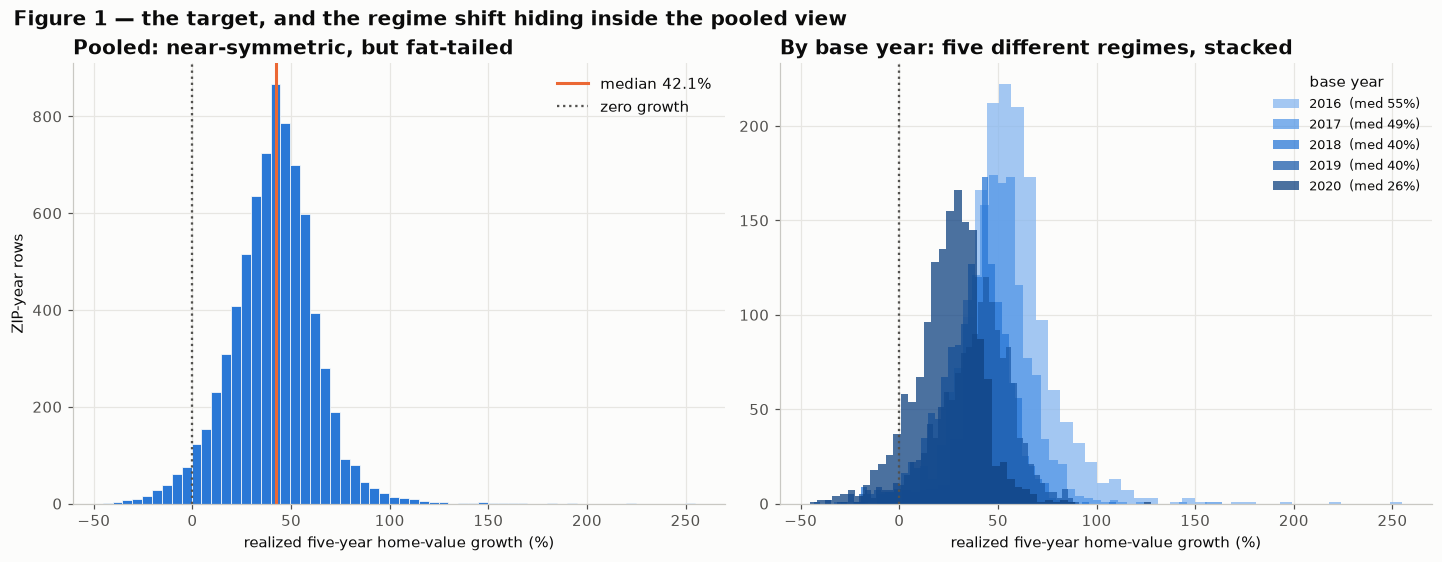

pooled   mean 41.2%   median 42.1%   sd 21.6   skew 0.31   excess kurtosis 3.80
negative-growth rows: 256 (3.4%)

            mean  median    std     min     max
base_year                                      
2016      57.900  55.300 21.000 -23.600 254.900
2017      48.300  48.800 17.700 -33.400 163.600
2018      37.900  40.100 17.300 -43.400 109.800
2019      38.200  40.400 19.000 -37.400  91.100
2020      24.300  26.200 17.300 -45.500 127.800


In [4]:
t = panel[TARGET]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")

ax = axes[0]
ax.hist(t, bins=60, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
ax.axvline(t.median(), color=ACCENT, lw=2, label=f"median {t.median():.1f}%")
ax.axvline(0, color=GRAY, lw=1.5, ls=":", label="zero growth")
ax.set_title("Pooled: near-symmetric, but fat-tailed")
ax.set_xlabel("realized five-year home-value growth (%)")
ax.set_ylabel("ZIP-year rows")
ax.legend()

ax = axes[1]
for (y, g), c in zip(panel.groupby("base_year"), YEAR_COLORS):
    ax.hist(g[TARGET], bins=45, color=c, alpha=0.75, histtype="stepfilled",
            label=f"{y}  (med {g[TARGET].median():.0f}%)")
ax.axvline(0, color=GRAY, lw=1.5, ls=":")
ax.set_title("By base year: five different regimes, stacked")
ax.set_xlabel("realized five-year home-value growth (%)")
ax.legend(title="base year", fontsize=8.5)

fig.suptitle("Figure 1 — the target, and the regime shift hiding inside the pooled view",
             x=0.005, ha="left", fontweight="bold", fontsize=13)
save(fig, "fig01_target_distribution")
plt.show()

print(f"pooled   mean {t.mean():.1f}%   median {t.median():.1f}%   sd {t.std():.1f}"
      f"   skew {t.skew():.2f}   excess kurtosis {t.kurt():.2f}")
print(f"negative-growth rows: {(t < 0).sum():,} ({(t < 0).mean():.1%})\n")
print(panel.groupby("base_year")[TARGET].agg(["mean", "median", "std", "min", "max"]).round(1).to_string())

## 2.2 Affordability — the strongest signal in the dataset

The hypothesis: *a market already priced beyond what local incomes can carry has less room left to
run.* The left panel shows it pooled. The right panel is the one that matters — the effect holds
**inside every single base year**, so it is a genuine cross-sectional relationship rather than a
macro coincidence produced by stacking five regimes.

Both `price_to_income_ratio` and `price_to_rent_ratio` are **engineered** features that beat their
own ingredients (income alone r ≈ −0.14; home value alone r ≈ −0.23). That is the best argument in
this dataset for ratio-building over raw columns.

Honest caveat: r ≈ −0.3 is a *moderate* effect, explaining roughly 9% of variance on its own.

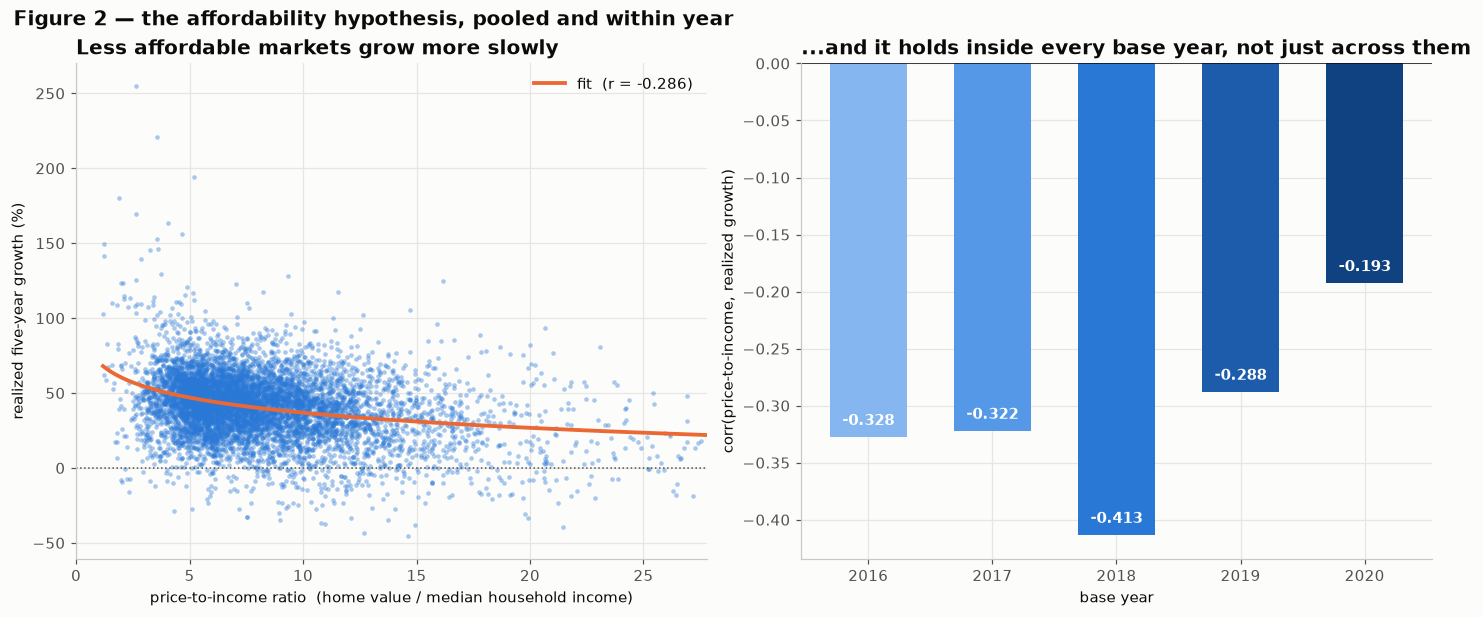

pooled  corr(price_to_income, growth) = -0.286
pooled  corr(price_to_rent,   growth) = -0.305

corr(income, home VALUE)  = 0.731
corr(income, future GROWTH) = -0.136
  -> prosperity is a LEVEL effect, not a GROWTH effect.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), layout="constrained")

ax = axes[0]
ax.scatter(panel["price_to_income_ratio"], panel[TARGET], s=9, alpha=0.4, color=BLUE, linewidths=0)
r_all = panel["price_to_income_ratio"].corr(panel[TARGET])
x = panel["price_to_income_ratio"].clip(lower=0.1)
b, a = np.polyfit(np.log(x), panel[TARGET], 1)          # log fit: the ratio is heavily right-skewed
xs = np.linspace(x.min(), x.quantile(0.995), 100)
ax.plot(xs, a + b * np.log(xs), color=ACCENT, lw=2.5, label=f"fit  (r = {r_all:.3f})")
ax.axhline(0, color=GRAY, lw=1, ls=":")
ax.set_xlim(0, panel["price_to_income_ratio"].quantile(0.995))
ax.set_title("Less affordable markets grow more slowly")
ax.set_xlabel("price-to-income ratio  (home value / median household income)")
ax.set_ylabel("realized five-year growth (%)")
ax.legend()

ax = axes[1]
within = panel.groupby("base_year").apply(
    lambda g: g["price_to_income_ratio"].corr(g[TARGET]), include_groups=False)
bars = ax.bar([str(y) for y in within.index], within.values, color=YEAR_COLORS, width=0.62)
for rect, v in zip(bars, within.values):
    ax.annotate(f"{v:.3f}", (rect.get_x() + rect.get_width() / 2, v), xytext=(0, 8),
                textcoords="offset points", ha="center", fontsize=9.5,
                color="white", fontweight="bold")
ax.axhline(0, color="#0b0b0b", lw=1)
ax.set_title("...and it holds inside every base year, not just across them")
ax.set_ylabel("corr(price-to-income, realized growth)")
ax.set_xlabel("base year")

fig.suptitle("Figure 2 — the affordability hypothesis, pooled and within year",
             x=0.005, ha="left", fontweight="bold", fontsize=13)
save(fig, "fig02_affordability")
plt.show()

print(f"pooled  corr(price_to_income, growth) = {r_all:.3f}")
print(f"pooled  corr(price_to_rent,   growth) = {panel['price_to_rent_ratio'].corr(panel[TARGET]):.3f}")
print(f"\ncorr(income, home VALUE)  = {panel['median_household_income'].corr(panel['current_home_value']):.3f}")
print(f"corr(income, future GROWTH) = {panel['median_household_income'].corr(panel[TARGET]):.3f}")
print("  -> prosperity is a LEVEL effect, not a GROWTH effect.")

## 2.3 Collinearity — why the project uses Ridge

Income, rent, education and home value all measure one latent thing: *how affluent this ZIP code
is.* Under plain OLS their coefficients become unstable and can flip sign under resampling — the
*explanation* becomes worthless even when the predictions are fine. **Ridge's L2 penalty shares
weight across correlated predictors instead of arbitrarily crowning one.** That is an empirical
response to the +0.84 in this matrix, not a stylistic preference.

The same collinearity is why per-feature permutation importance is untrustworthy here (§4.4) and
why §8 leans on *grouped* permutation instead.

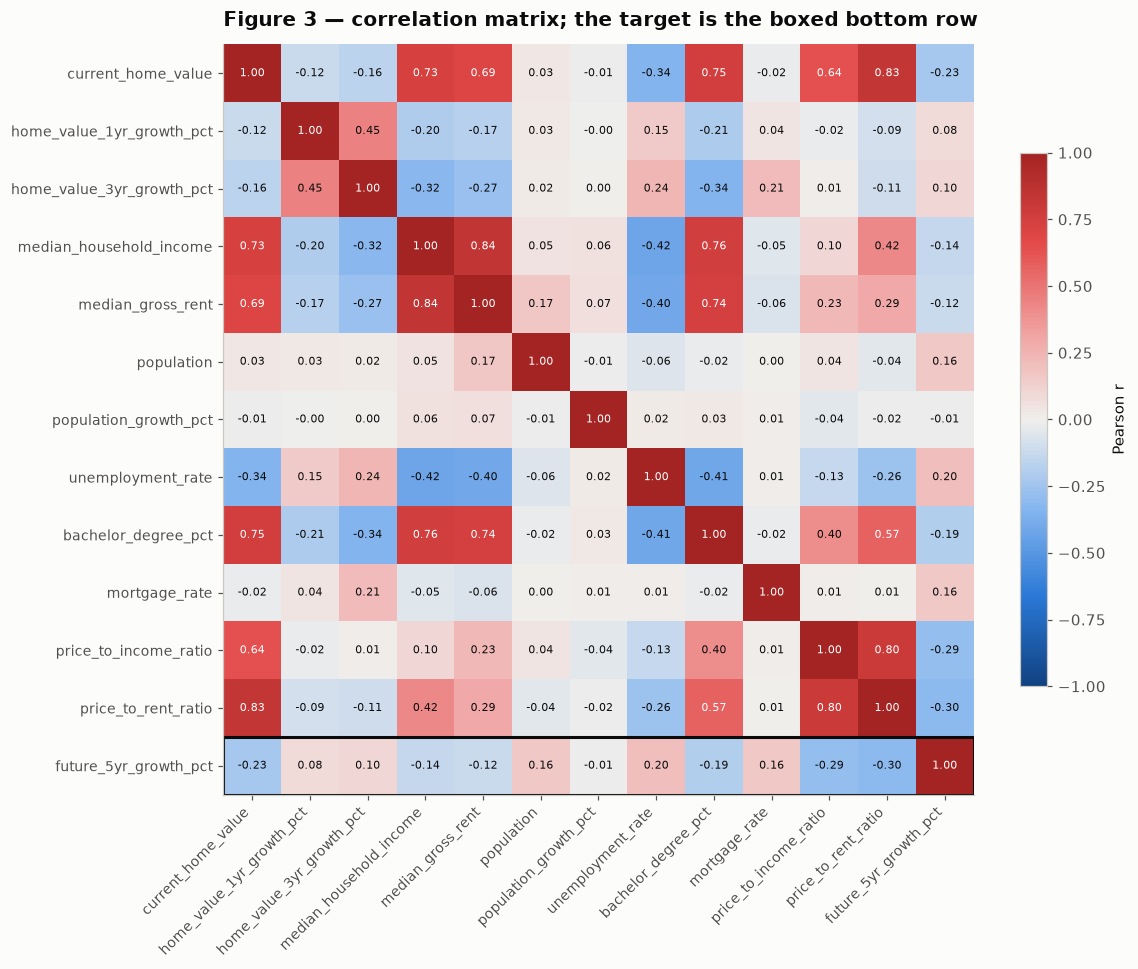

The affluence block -- one latent variable wearing four names:
  median_household_income    <-> median_gross_rent          r = +0.838
  bachelor_degree_pct        <-> median_household_income    r = +0.764
  current_home_value         <-> bachelor_degree_pct        r = +0.753


In [6]:
CORE = ["current_home_value", "home_value_1yr_growth_pct", "home_value_3yr_growth_pct",
        "median_household_income", "median_gross_rent", "population", "population_growth_pct",
        "unemployment_rate", "bachelor_degree_pct", "mortgage_rate",
        "price_to_income_ratio", "price_to_rent_ratio", TARGET]
corr = panel[CORE].corr()

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(CORE)), CORE, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(CORE)), CORE, fontsize=9)
for i in range(len(CORE)):
    for j in range(len(CORE)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(v) > 0.55 else "#0b0b0b")
ax.add_patch(plt.Rectangle((-0.5, len(CORE) - 1.5), len(CORE), 1, fill=False,
                           edgecolor="#0b0b0b", lw=2))
ax.set_title("Figure 3 — correlation matrix; the target is the boxed bottom row", pad=12)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="Pearson r")
save(fig, "fig03_correlation_heatmap")
plt.show()

print("The affluence block -- one latent variable wearing four names:")
for a, b in [("median_household_income", "median_gross_rent"),
             ("bachelor_degree_pct", "median_household_income"),
             ("current_home_value", "bachelor_degree_pct")]:
    print(f"  {a:<26} <-> {b:<26} r = {corr.loc[a, b]:+.3f}")

## 2.4 No single dominant predictor

Nothing in the panel exceeds |r| = 0.31. Five-year growth is genuinely **multivariate**, and this
sets the expectation for §4: a realistic R² is in the 0.1–0.4 band. **An R² near 0.9 here should be
read as evidence of leakage** — most likely `future_5yr_home_value` left in the feature matrix —
not as success.

Two entries in this chart are traps:

- **Momentum is nearly useless at a five-year horizon.** The most intuitive feature in real estate
  — "it has been going up, so it will keep going up" — has r ≈ +0.08 and +0.10.
- **`mortgage_rate` is a `base_year` proxy.** It is national, so every ZIP in a given year receives
  the identical value. With five base years it is effectively five data points, perfectly
  confounded with `base_year`. Its r = +0.16 is a base-year effect wearing a feature's name. §4.5
  demonstrates this rather than asserting it.

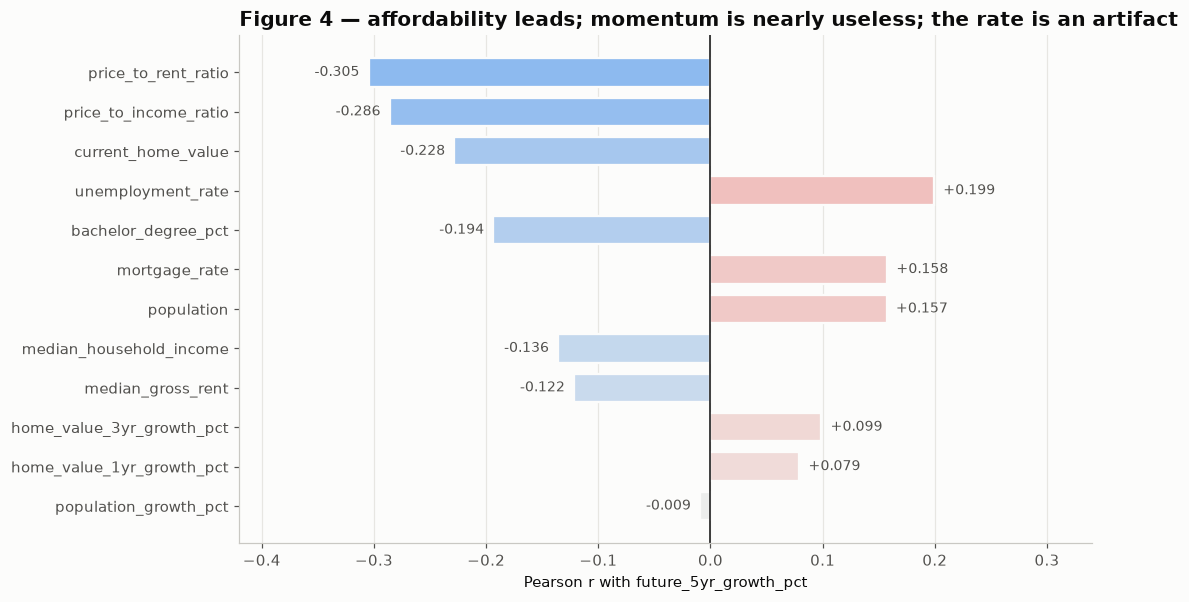

correlation with the target, strongest first:
price_to_rent_ratio         -0.305
price_to_income_ratio       -0.286
current_home_value          -0.228
unemployment_rate            0.199
bachelor_degree_pct         -0.194
mortgage_rate                0.158
population                   0.157
median_household_income     -0.136
median_gross_rent           -0.122
home_value_3yr_growth_pct    0.099
home_value_1yr_growth_pct    0.079
population_growth_pct       -0.009


In [7]:
target_corr = corr[TARGET].drop(TARGET).sort_values(key=abs)

fig, ax = plt.subplots(figsize=(10, 6))
colors = [DIVERGING(0.5 + v / 2) for v in target_corr.values]
ax.barh(target_corr.index, target_corr.values, color=colors, height=0.72,
        edgecolor="#fcfcfb", linewidth=1.5)
for i, v in enumerate(target_corr.values):
    ax.annotate(f"{v:+.3f}", (v, i), xytext=(6 if v > 0 else -6, 0), textcoords="offset points",
                va="center", ha="left" if v > 0 else "right", fontsize=9, color=GRAY)
ax.axvline(0, color="#0b0b0b", lw=1)
ax.set_xlim(-0.42, 0.34)
ax.set_xlabel(f"Pearson r with {TARGET}")
ax.set_title("Figure 4 — affordability leads; momentum is nearly useless; the rate is an artifact")
ax.grid(axis="y", visible=False)
save(fig, "fig04_target_correlations")
plt.show()

print("correlation with the target, strongest first:")
print(target_corr.sort_values(key=abs, ascending=False).round(3).to_string())

## 2.5 The outliers we kept

The left panel is the argument for keeping them: flagged rows sit at **both** extremes of the
outcome and across the **whole** price range. They are unusual outcomes, not corrupted
measurements. The right panel shows the flag counts are stable across base years — the consequence
of computing IQR bounds *within* year rather than pooling.

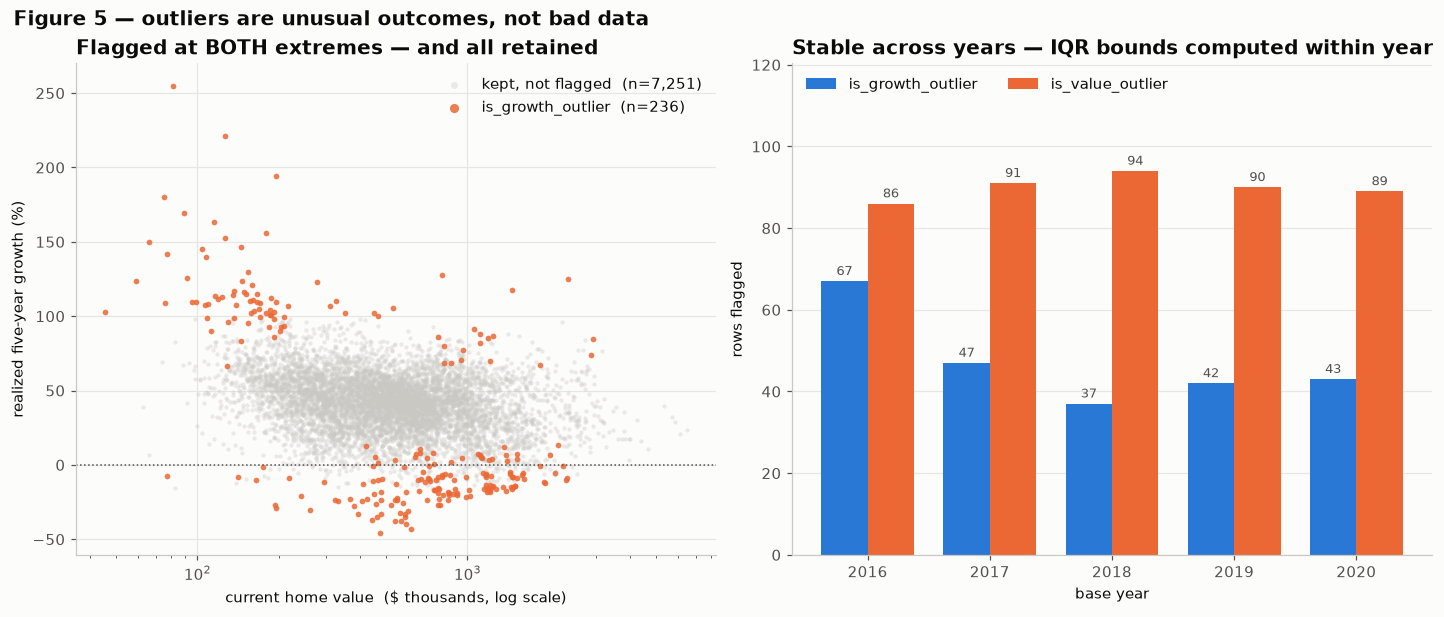

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), layout="constrained")

ax = axes[0]
normal, out = panel[panel.is_growth_outlier == 0], panel[panel.is_growth_outlier == 1]
ax.scatter(normal["current_home_value"] / 1000, normal[TARGET], s=8, alpha=0.35,
           color="#c9c8c3", linewidths=0, label=f"kept, not flagged  (n={len(normal):,})")
ax.scatter(out["current_home_value"] / 1000, out[TARGET], s=14, alpha=0.85,
           color=ACCENT, linewidths=0, label=f"is_growth_outlier  (n={len(out):,})")
ax.set_xscale("log")
ax.axhline(0, color=GRAY, lw=1, ls=":")
ax.set_xlabel("current home value  ($ thousands, log scale)")
ax.set_ylabel("realized five-year growth (%)")
ax.set_title("Flagged at BOTH extremes — and all retained")
ax.legend(markerscale=1.6, loc="upper right")

ax = axes[1]
counts = panel.groupby("base_year")[["is_growth_outlier", "is_value_outlier"]].sum()
w, xs = 0.38, np.arange(len(counts))
b1 = ax.bar(xs - w / 2, counts["is_growth_outlier"], w, color=BLUE, label="is_growth_outlier")
b2 = ax.bar(xs + w / 2, counts["is_value_outlier"], w, color=ACCENT, label="is_value_outlier")
for bars in (b1, b2):
    ax.bar_label(bars, fontsize=8.5, color=GRAY, padding=2)
ax.set_xticks(xs, [str(y) for y in counts.index])
ax.set_xlabel("base year"); ax.set_ylabel("rows flagged")
ax.set_title("Stable across years — IQR bounds computed within year")
ax.set_ylim(0, counts.values.max() * 1.28)
ax.legend(loc="upper left", ncol=2)
ax.grid(axis="x", visible=False)

fig.suptitle("Figure 5 — outliers are unusual outcomes, not bad data",
             x=0.005, ha="left", fontweight="bold", fontsize=13)
save(fig, "fig05_outliers")
plt.show()

---
# 3. Feature engineering and the temporal split

## 3.1 Three engineered features

`price_to_income_ratio` measures affordability **at cash prices**, which is not what a buyer
actually faces. What a household can carry is a *monthly payment*, and that depends on the mortgage
rate as well as the price. So:

- `estimated_monthly_mortgage` — the standard amortization formula on 80% of the home value over
  360 months at that year's rate.
- `mortgage_to_income_ratio` — that payment divided by monthly median income. **This is the
  affordability measure a lender would actually use.**
- `rent_to_income_ratio` — annual rent burden, the renter-side analogue.

`mortgage_to_income_ratio` is a *within-year* monotone transform of `price_to_income_ratio` (the
rate is constant within a year), so their within-year correlations with the target are identical.
It differs from it only **across** years — which is exactly where it adds information and exactly
where the panel has only five points. Both are kept and both are reported in §8 as one block.

In [9]:
def engineer(d: pd.DataFrame) -> pd.DataFrame:
    """The three D2 features. Applied identically to the panel and to the 2024 forecast frame."""
    d = d.copy()
    r = d["mortgage_rate"] / 100 / 12           # monthly rate
    n = 360                                     # 30-year term, in months
    principal = d["current_home_value"] * 0.80  # 20% down

    d["estimated_monthly_mortgage"] = principal * r * (1 + r) ** n / ((1 + r) ** n - 1)
    d["mortgage_to_income_ratio"] = (
        d["estimated_monthly_mortgage"] / (d["median_household_income"] / 12))
    d["rent_to_income_ratio"] = d["median_gross_rent"] * 12 / d["median_household_income"]
    return d


panel = engineer(panel)
NEW = ["estimated_monthly_mortgage", "mortgage_to_income_ratio", "rent_to_income_ratio"]

rows = []
for c in ["price_to_income_ratio", "price_to_rent_ratio"] + NEW:
    row = {"feature": c, "pooled r": panel[c].corr(panel[TARGET])}
    for y, g in panel.groupby("base_year"):
        row[str(y)] = g[c].corr(g[TARGET])
    rows.append(row)
print("Correlation with the target -- pooled, and inside each base year")
print(pd.DataFrame(rows).set_index("feature").round(3).to_string())

Correlation with the target -- pooled, and inside each base year
                            pooled r   2016   2017   2018   2019   2020
feature                                                                
price_to_income_ratio         -0.286 -0.328 -0.322 -0.413 -0.288 -0.193
price_to_rent_ratio           -0.305 -0.376 -0.386 -0.415 -0.278 -0.135
estimated_monthly_mortgage    -0.219 -0.317 -0.303 -0.322 -0.117  0.027
mortgage_to_income_ratio      -0.268 -0.328 -0.322 -0.413 -0.288 -0.193
rent_to_income_ratio           0.047  0.202  0.031  0.041  0.006 -0.086


## 3.2 The split — temporal, never random

**7,487 rows are not 7,487 independent observations.** Base years 2016–2020 produce outcome
windows 2021–2025 that overlap heavily: the 2016 and 2017 rows for a given ZIP code share four
years of price history. A random 80/20 split would put 2016-Fresno in training and 2017-Fresno in
test and report a flattering, meaningless R².

So: **train 2016–2018 / validate 2019 / test 2020**, and every cross-validation uses `GroupKFold`
grouped on `base_year`. Plain `KFold` appears nowhere in this project.

This split is also the honest simulation of the actual use case: *use the past to predict a year
you have not seen.*

Note the mean growth in each split — 48.0% / 38.2% / 24.3%. The split is not just temporal, it is
**across three different market regimes**. §4 is the consequence.

In [10]:
FEATURES = [
    # --- D1 core (12) ---
    "current_home_value", "home_value_1yr_growth_pct", "home_value_3yr_growth_pct",
    "median_household_income", "median_gross_rent", "population", "population_growth_pct",
    "unemployment_rate", "bachelor_degree_pct", "mortgage_rate",
    "price_to_income_ratio", "price_to_rent_ratio",
    # --- engineered (3) ---
    "estimated_monthly_mortgage", "mortgage_to_income_ratio", "rent_to_income_ratio",
]

# Leakage guards. is_growth_outlier / is_value_outlier look like ordinary data-quality columns and
# are in fact derived from the target -- they contain part of the answer.
LEAKY = ["future_5yr_home_value", "is_growth_outlier", "is_value_outlier"]
assert not any(c in FEATURES for c in LEAKY), "a target-derived column reached the feature matrix"
assert "base_year" not in FEATURES, "base_year must not be a feature -- it is the split variable"
assert panel[FEATURES].isna().sum().sum() == 0, "unexpected nulls in the feature matrix"

TRAIN_YEARS, VAL_YEAR, TEST_YEAR = [2016, 2017, 2018], 2019, 2020
train = panel[panel["base_year"].isin(TRAIN_YEARS)]
val   = panel[panel["base_year"] == VAL_YEAR]
test  = panel[panel["base_year"] == TEST_YEAR]

X_train, y_train = train[FEATURES], train[TARGET]
X_val,   y_val   = val[FEATURES],   val[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]
groups = train["base_year"]                 # <- CV groups, never a feature

print(f"features  {len(FEATURES)}")
print(f"train {TRAIN_YEARS}  {len(train):>5,} rows   mean growth {y_train.mean():6.2f}%")
print(f"val   [{VAL_YEAR}]              {len(val):>5,} rows   mean growth {y_val.mean():6.2f}%")
print(f"test  [{TEST_YEAR}]              {len(test):>5,} rows   mean growth {y_test.mean():6.2f}%")

assert set(train["base_year"]) & set(val["base_year"]) == set()
assert set(train["base_year"]) & set(test["base_year"]) == set()
print("\nleakage assertions passed: splits share no base year, no target-derived feature present")

features  15
train [2016, 2017, 2018]  4,448 rows   mean growth  47.96%
val   [2019]              1,511 rows   mean growth  38.15%
test  [2020]              1,528 rows   mean growth  24.31%

leakage assertions passed: splits share no base year, no target-derived feature present


---
# 4. Regression — and the failure that is the project's central finding

Four models: a mean baseline (the thing every model must beat), Ridge (chosen for the collinearity
in §2.3, `alpha` selected by leave-one-base-year-out CV), Random Forest, and Gradient Boosting.

In [11]:
def fit_ridge_alpha(X, y, groups, alphas=np.logspace(-2, 4, 25)):
    """Choose Ridge's alpha by leave-one-base-year-out CV RMSE. No plain KFold."""
    gkf = GroupKFold(n_splits=3)
    scores = []
    for a in alphas:
        pipe = Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=a))])
        scores.append(np.sqrt(mean_squared_error(
            y, cross_val_predict(pipe, X, y, cv=gkf, groups=groups))))
    return alphas[int(np.argmin(scores))], pd.Series(scores, index=np.round(alphas, 3))


def make_models(alpha):
    return {
        "Baseline (mean)": DummyRegressor(strategy="mean"),
        "Ridge": Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=alpha))]),
        "Random Forest": RandomForestRegressor(
            n_estimators=400, min_samples_leaf=5, max_features=0.5,
            random_state=RANDOM_STATE, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(
            n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8,
            random_state=RANDOM_STATE),
    }


def metrics(y, pred) -> dict:
    mse = mean_squared_error(y, pred)
    return {"R2": r2_score(y, pred), "MSE": mse,
            "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y, pred)}


def evaluate(models, X_tr, y_tr, g, X_v, y_v, X_te, y_te):
    gkf = GroupKFold(n_splits=3)
    rows, fitted, preds = [], {}, {}
    for name, model in models.items():
        cv_rmse = np.sqrt(mean_squared_error(
            y_tr, cross_val_predict(model, X_tr, y_tr, cv=gkf, groups=g)))
        model.fit(X_tr, y_tr)
        fitted[name] = model
        p_tr, p_v, p_te = model.predict(X_tr), model.predict(X_v), model.predict(X_te)
        preds[name] = {"train": p_tr, "val": p_v, "test": p_te}
        mv, mt, mtr = metrics(y_v, p_v), metrics(y_te, p_te), metrics(y_tr, p_tr)
        rows.append({"Model": name, "CV RMSE": cv_rmse, "Train R2": mtr["R2"],
                     "Val RMSE": mv["RMSE"], "Val MAE": mv["MAE"], "Val R2": mv["R2"],
                     "Test RMSE": mt["RMSE"], "Test MAE": mt["MAE"], "Test R2": mt["R2"]})
    return pd.DataFrame(rows).set_index("Model"), fitted, preds


best_alpha, _ = fit_ridge_alpha(X_train, y_train, groups)
print(f"selected Ridge alpha = {best_alpha:,.1f}  "
      f"(a large penalty -- exactly what collinear predictors call for)\n")

results, fitted, preds = evaluate(make_models(best_alpha), X_train, y_train, groups,
                                  X_val, y_val, X_test, y_test)
results.round(3)

selected Ridge alpha = 1,778.3  (a large penalty -- exactly what collinear predictors call for)



,CV RMSE,Train R2,Val RMSE,Val MAE,Val R2,Test RMSE,Test MAE,Test R2
Model,,,,,,,,
Baseline (mean),22.330,0.000,21.382,15.962,-0.266,29.277,24.776,-1.875
Ridge,17.763,0.319,20.973,15.877,-0.218,40.518,37.172,-4.506
Random Forest,18.055,0.801,19.425,14.642,-0.045,33.873,29.501,-2.848
Gradient Boosting,17.708,0.702,19.041,14.328,-0.004,35.495,31.423,-3.226


## 4.1 What that table says

- **Cross-validation and 2019 validation:** every model beats the baseline. The features do carry
  predictive information.
- **2020 test:** every model *loses to a constant*. All four test R² values are **negative**, and
  the most flexible models are the most wrong.

A negative R² is not a bug. It means the model is worse than predicting the training mean for every
row. This is the single most important result in the project, and §4.2 diagnoses it rather than
hiding it.

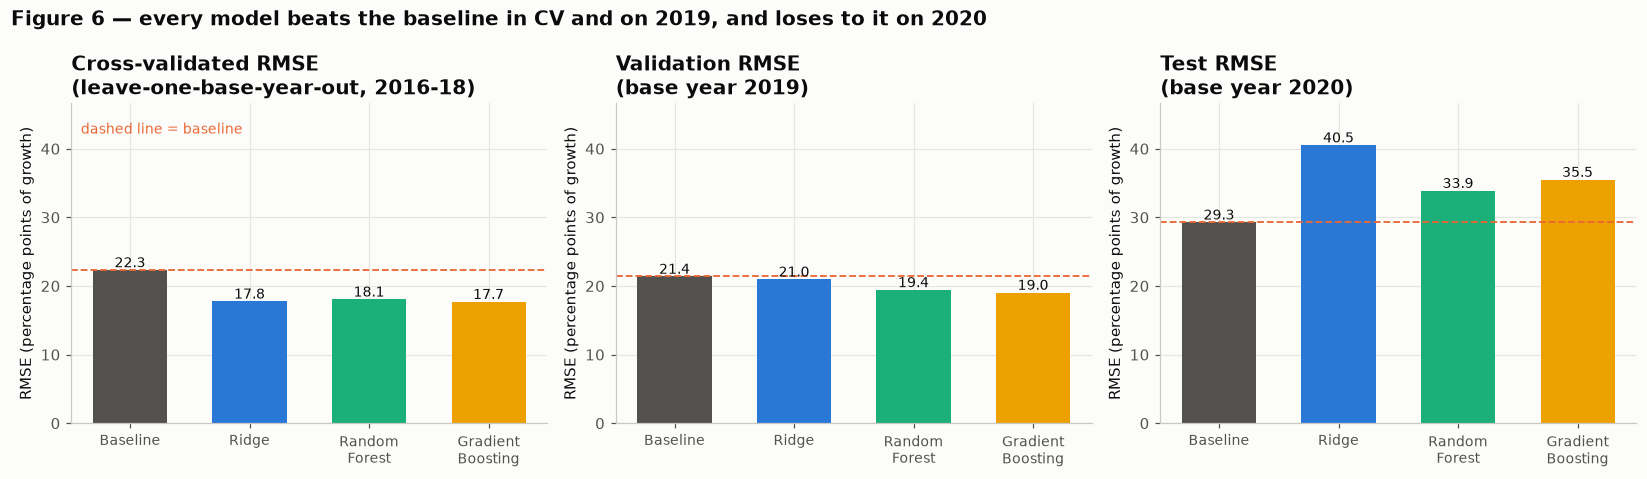

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
order = list(results.index)
colors = CATEGORICAL[:len(order)]

for ax, col, title in zip(
    axes, ["CV RMSE", "Val RMSE", "Test RMSE"],
    ["Cross-validated RMSE\n(leave-one-base-year-out, 2016-18)",
     "Validation RMSE\n(base year 2019)", "Test RMSE\n(base year 2020)"]):
    ax.bar(range(len(order)), results.loc[order, col], color=colors, width=0.62)
    for i, v in enumerate(results.loc[order, col]):
        ax.text(i, v + 0.4, f"{v:.1f}", ha="center", fontsize=9)
    ax.axhline(results.loc["Baseline (mean)", col], color=ACCENT, ls="--", lw=1.2)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([o.replace(" (mean)", "").replace(" ", "\n") for o in order], fontsize=9)
    ax.set_title(title)
    ax.set_ylabel("RMSE (percentage points of growth)")
    ax.set_ylim(0, max(results["Test RMSE"]) * 1.15)
axes[0].text(0.02, 0.94, "dashed line = baseline", transform=axes[0].transAxes,
             color=ACCENT, fontsize=9, va="top")

fig.suptitle("Figure 6 — every model beats the baseline in CV and on 2019, and loses to it on 2020",
             x=0.005, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "fig06_model_comparison")
plt.show()

## 4.2 Diagnosis: the error is a level shift, not noise

Decompose the test MSE. If the models were simply noisy, the residuals would be centred on zero. If
they are *biased* — predicting a boom that did not arrive — the residuals will be centred somewhere
far from zero, and most of the MSE will be attributable to that single number.

`bias² / MSE` answers this directly, and `debiased R²` asks what would be left if the level shift
were removed and only the ranking judged.

In [13]:
rows = []
for name in order:
    p = preds[name]["test"]
    bias = p.mean() - y_test.mean()
    sp = spearmanr(y_test, p).statistic if np.std(p) > 1e-9 else np.nan
    rows.append({"Model": name,
                 "Test RMSE": np.sqrt(mean_squared_error(y_test, p)),
                 "bias (pred - actual)": bias,
                 "share of MSE from bias": bias ** 2 / mean_squared_error(y_test, p),
                 "debiased RMSE": np.sqrt(mean_squared_error(y_test, p - bias)),
                 "debiased R2": r2_score(y_test, p - bias),
                 "Spearman rank corr": sp})
decomp = pd.DataFrame(rows).set_index("Model")
print(f"standard deviation of actual 2020 growth: {y_test.std():.2f} percentage points")
print("(so a model that only knew the 2020 mean would already have RMSE ~17.3)\n")
decomp.round(3)

standard deviation of actual 2020 growth: 17.27 percentage points
(so a model that only knew the 2020 mean would already have RMSE ~17.3)



,Test RMSE,bias (pred - actual),share of MSE from bias,debiased RMSE,debiased R2,Spearman rank corr
Model,,,,,,
Baseline (mean),29.277,23.643,0.652,17.267,0.000,NaN
Ridge,40.518,36.560,0.814,17.466,-0.023,0.209
Random Forest,33.873,28.955,0.731,17.579,-0.036,0.248
Gradient Boosting,35.495,30.983,0.762,17.319,-0.006,0.314


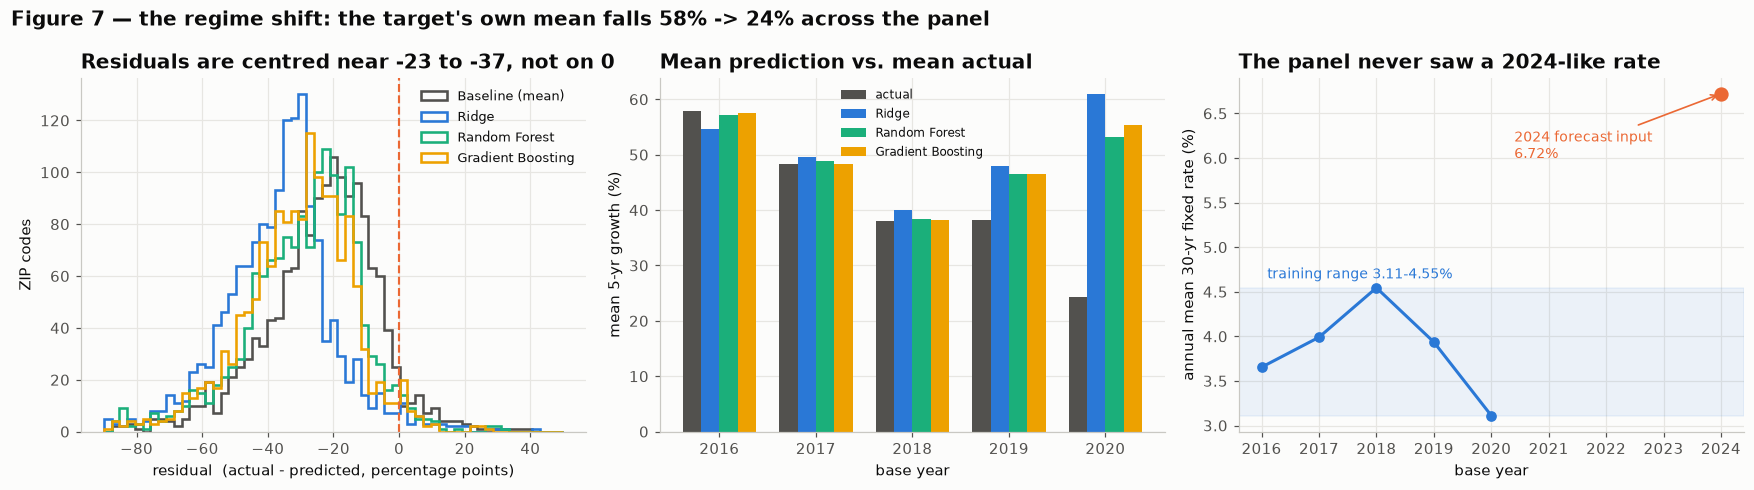

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

ax = axes[0]
for name, color in zip(order, colors):
    ax.hist(y_test - preds[name]["test"], bins=np.linspace(-90, 50, 60),
            histtype="step", lw=1.7, color=color, label=name)
ax.axvline(0, color=ACCENT, lw=1.4, ls="--")
ax.set_xlabel("residual  (actual - predicted, percentage points)")
ax.set_ylabel("ZIP codes")
ax.set_title("Residuals are centred near -23 to -37, not on 0")
ax.legend(fontsize=8.5)

ax = axes[1]
by_year = panel.groupby("base_year").agg(mean_growth=(TARGET, "mean"),
                                         mortgage_rate=("mortgage_rate", "first")).reset_index()
xs = np.arange(len(by_year))
w = 0.19
ax.bar(xs - 1.5 * w, by_year["mean_growth"], w, color=GRAY, label="actual")
for k, (name, color) in enumerate(zip(order[1:], colors[1:])):
    pm = [fitted[name].predict(panel[panel.base_year == y][FEATURES]).mean()
          for y in by_year["base_year"]]
    ax.bar(xs + (k - 0.5) * w, pm, w, color=color, label=name)
ax.set_xticks(xs); ax.set_xticklabels(by_year["base_year"].astype(str))
ax.set_xlabel("base year"); ax.set_ylabel("mean 5-yr growth (%)")
ax.set_title("Mean prediction vs. mean actual")
ax.legend(fontsize=8)

ax = axes[2]
ax.plot(by_year["base_year"], by_year["mortgage_rate"], marker="o", color=BLUE, lw=2)
ax.scatter([2024], [6.721], color=ACCENT, s=70, zorder=5)
ax.annotate("2024 forecast input\n6.72%", (2024, 6.721), xytext=(2020.4, 6.0), color=ACCENT,
            fontsize=9, arrowprops=dict(arrowstyle="->", color=ACCENT, lw=1.1))
ax.axhspan(by_year["mortgage_rate"].min(), by_year["mortgage_rate"].max(), color=BLUE, alpha=0.08)
ax.text(2016.1, 4.65, "training range 3.11-4.55%", color=BLUE, fontsize=9)
ax.set_xlabel("base year"); ax.set_ylabel("annual mean 30-yr fixed rate (%)")
ax.set_title("The panel never saw a 2024-like rate")

fig.suptitle("Figure 7 — the regime shift: the target's own mean falls 58% -> 24% across the panel",
             x=0.005, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "fig07_regime_shift")
plt.show()

**The verdict.** Between 65% and 81% of the test MSE comes from a single number: the models predict
a boom-era average and 2020 did not deliver one. Debiased R² is ≈ 0, but Spearman rank correlation
stays positive (0.21–0.31) — **the ordering of ZIP codes survives; the level does not.**

That distinction is worth more than any R². It says the models learned *what kind of ZIP code
outperforms*, and failed at *how much California as a whole would grow* — because the second thing
is macroeconomics, and there are only five macro observations in this panel.

## 4.3 Fixing the target: predict relative, not absolute, growth

If the statewide level is unlearnable from cross-sectional features, stop asking the model to learn
it. Redefine the target as **growth relative to the median ZIP code in the same base year**:

```python
rel_growth = future_5yr_growth_pct - median(future_5yr_growth_pct | base_year)
```

The question changes from *"how much will California grow?"* to *"will this ZIP code beat the rest
of California over the same window?"* — which is the question a buyer or planner can actually act
on, and the one the features are capable of answering.

`mortgage_rate` and `estimated_monthly_mortgage` are also dropped here: both are constant or
near-constant within a base year, so within the test year they carry exactly zero ranking
information (demonstrated in §4.5).

In [15]:
NO_RATE = [f for f in FEATURES if f not in ("mortgage_rate", "estimated_monthly_mortgage")]
panel["rel_growth"] = panel[TARGET] - panel.groupby("base_year")[TARGET].transform("median")

train_r = panel[panel.base_year.isin(TRAIN_YEARS)]
val_r   = panel[panel.base_year == VAL_YEAR]
test_r  = panel[panel.base_year == TEST_YEAR]

alpha_rel, _ = fit_ridge_alpha(train_r[NO_RATE], train_r["rel_growth"], groups)
results_rel, fitted_rel, preds_rel = evaluate(
    make_models(alpha_rel), train_r[NO_RATE], train_r["rel_growth"], groups,
    val_r[NO_RATE], val_r["rel_growth"], test_r[NO_RATE], test_r["rel_growth"])

results_rel["Spearman (test)"] = [
    spearmanr(test_r["rel_growth"], preds_rel[n]["test"]).statistic
    if np.std(preds_rel[n]["test"]) > 1e-9 else np.nan for n in results_rel.index]

print(f"{len(NO_RATE)} features (rate features dropped)\n")
results_rel[["CV RMSE", "Val RMSE", "Val R2", "Test RMSE", "Test MAE",
             "Test R2", "Spearman (test)"]].round(3)

13 features (rate features dropped)



,CV RMSE,Val RMSE,Val R2,Test RMSE,Test MAE,Test R2,Spearman (test)
Model,,,,,,,
Baseline (mean),18.933,19.136,-0.014,17.367,13.025,-0.012,NaN
Ridge,17.212,18.569,0.045,17.434,12.639,-0.019,0.228
Random Forest,15.196,15.986,0.292,16.240,12.020,0.115,0.408
Gradient Boosting,15.939,17.015,0.198,16.190,11.949,0.121,0.420


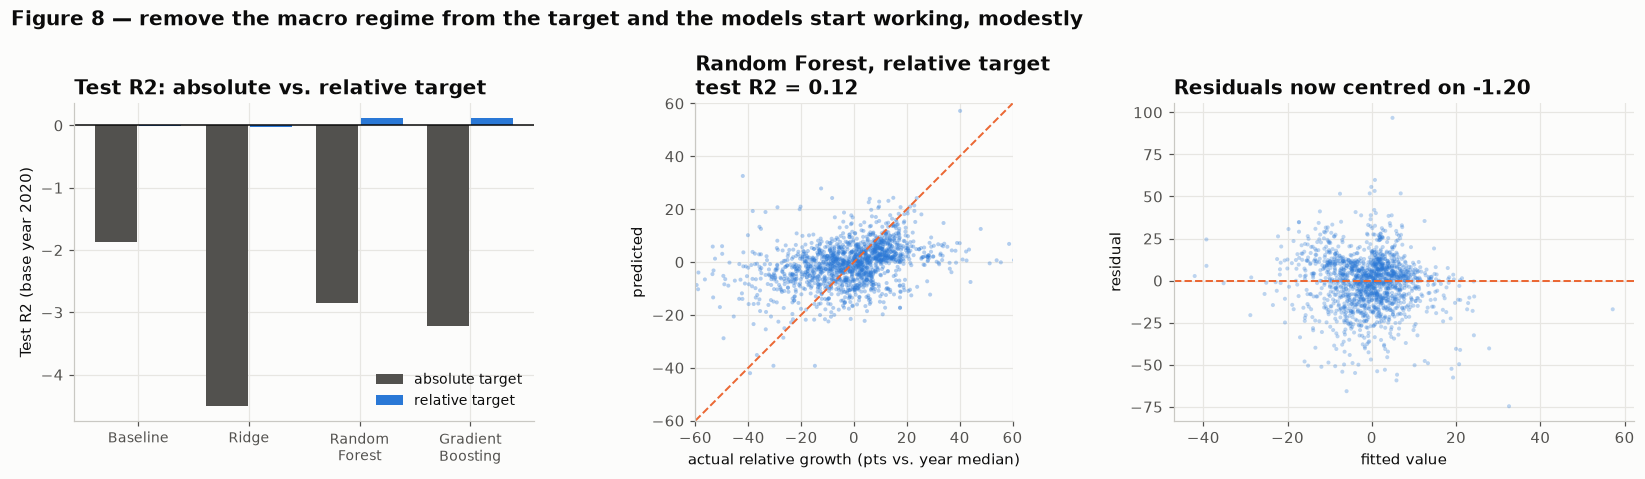

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

ax = axes[0]
labels = ["Baseline", "Ridge", "Random\nForest", "Gradient\nBoosting"]
x = np.arange(4)
ax.bar(x - 0.2, results["Test R2"], 0.38, color=GRAY, label="absolute target")
ax.bar(x + 0.2, results_rel["Test R2"], 0.38, color=BLUE, label="relative target")
ax.axhline(0, color="#0b0b0b", lw=1)
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel("Test R2 (base year 2020)")
ax.set_title("Test R2: absolute vs. relative target")
ax.legend(fontsize=9)

ax = axes[1]
p = preds_rel["Random Forest"]["test"]
ax.scatter(test_r["rel_growth"], p, s=7, alpha=0.35, color=BLUE, edgecolor="none")
lo, hi = -60, 60
ax.plot([lo, hi], [lo, hi], color=ACCENT, ls="--", lw=1.3)
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
ax.set_xlabel("actual relative growth (pts vs. year median)"); ax.set_ylabel("predicted")
ax.set_title(f"Random Forest, relative target\ntest R2 = {results_rel.loc['Random Forest','Test R2']:.2f}")

ax = axes[2]
res_rf = test_r["rel_growth"].to_numpy() - p
ax.scatter(p, res_rf, s=7, alpha=0.3, color=BLUE, edgecolor="none")
ax.axhline(0, color=ACCENT, ls="--", lw=1.3)
ax.set_xlabel("fitted value"); ax.set_ylabel("residual")
ax.set_title(f"Residuals now centred on {res_rf.mean():+.2f}")

fig.suptitle("Figure 8 — remove the macro regime from the target and the models start working, modestly",
             x=0.005, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "fig08_relative_target")
plt.show()

Random Forest and Gradient Boosting reach **test R² ≈ 0.12** with **Spearman ≈ 0.41** on a year
they never saw. That is modest and it is real. It is also the correct ceiling to quote for this
project: **ZIP-level features rank markets; they do not forecast the market.**

## 4.4 Feature importance — three views, only one of which can be trusted

Under the collinearity of §2.3, single-feature permutation importance is actively misleading:
shuffling `price_to_income_ratio` alone barely hurts, because `mortgage_to_income_ratio` is still
sitting there carrying the same information. The fix is to permute a whole correlated **block** at
once, so a feature's twin cannot cover for it.

In [17]:
ridge_rel = fitted_rel["Ridge"]
coefs = pd.Series(ridge_rel.named_steps["model"].coef_, index=NO_RATE)

def perm_imp(model, X, y, n_repeats=20):
    pi = permutation_importance(model, X, y, n_repeats=n_repeats, random_state=RANDOM_STATE,
                                scoring="neg_root_mean_squared_error")
    return pd.Series(pi.importances_mean, index=X.columns)

perm_rf = perm_imp(fitted_rel["Random Forest"], test_r[NO_RATE], test_r["rel_growth"])

BLOCKS = {
    "Affordability":   ["price_to_income_ratio", "price_to_rent_ratio",
                        "mortgage_to_income_ratio", "rent_to_income_ratio"],
    "Affluence level": ["current_home_value", "median_household_income",
                        "median_gross_rent", "bachelor_degree_pct"],
    "Urban scale":     ["population", "population_growth_pct"],
    "Momentum":        ["home_value_1yr_growth_pct", "home_value_3yr_growth_pct"],
    "Labor market":    ["unemployment_rate"],
}
assert sorted(c for cols in BLOCKS.values() for c in cols) == sorted(NO_RATE)

def grouped_perm(model, X, y, blocks, n_repeats=20):
    """Permute a whole correlated block at once, keeping within-block structure intact."""
    base = np.sqrt(mean_squared_error(y, model.predict(X)))
    out = {}
    for name, cols in blocks.items():
        deltas = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[cols] = Xp[cols].to_numpy()[rng.permutation(len(Xp))]
            deltas.append(np.sqrt(mean_squared_error(y, model.predict(Xp))) - base)
        out[name] = float(np.mean(deltas))
    return pd.Series(out)

grouped = pd.DataFrame({
    "Ridge (val 2019)":  grouped_perm(ridge_rel, val_r[NO_RATE], val_r["rel_growth"], BLOCKS),
    "Ridge (test 2020)": grouped_perm(ridge_rel, test_r[NO_RATE], test_r["rel_growth"], BLOCKS),
    "RF (val 2019)":     grouped_perm(fitted_rel["Random Forest"], val_r[NO_RATE], val_r["rel_growth"], BLOCKS),
    "RF (test 2020)":    grouped_perm(fitted_rel["Random Forest"], test_r[NO_RATE], test_r["rel_growth"], BLOCKS),
})
grouped["mean"] = grouped.mean(axis=1)
grouped = grouped.sort_values("mean", ascending=False)
print("Grouped permutation importance -- RMSE increase when the whole block is shuffled")
print(grouped.round(3).to_string())

Grouped permutation importance -- RMSE increase when the whole block is shuffled
                 Ridge (val 2019)  Ridge (test 2020)  RF (val 2019)  RF (test 2020)   mean
Urban scale                 0.525              0.513          2.751           2.373  1.541
Affordability               1.477              0.816          2.700           0.855  1.462
Affluence level            -0.238             -0.314          1.124           0.274  0.211
Momentum                   -0.315              0.179          0.400           0.103  0.092
Labor market               -0.142             -0.194          0.175          -0.083 -0.061


In [18]:
# Does each association hold across base years, or does its sign flip? A predictor whose direction
# is not stable across regimes cannot be called primary, however large its coefficient.
stability = pd.DataFrame(
    {str(y): [g[c].corr(g["rel_growth"]) for c in NO_RATE] for y, g in panel.groupby("base_year")},
    index=NO_RATE)
stability["sign consistent"] = np.where(
    (stability.iloc[:, :5] > 0).all(axis=1) | (stability.iloc[:, :5] < 0).all(axis=1), "yes", "FLIPS")
print("Correlation with RELATIVE growth, within each base year")
print(stability.round(3).to_string())

Correlation with RELATIVE growth, within each base year
                            2016   2017   2018   2019   2020 sign consistent
current_home_value        -0.317 -0.303 -0.322 -0.117  0.027           FLIPS
home_value_1yr_growth_pct  0.139  0.409 -0.116 -0.001  0.304           FLIPS
home_value_3yr_growth_pct -0.032  0.091  0.081  0.123  0.085           FLIPS
median_household_income   -0.259 -0.208 -0.143  0.065  0.162           FLIPS
median_gross_rent         -0.223 -0.198 -0.128  0.113  0.186           FLIPS
population                 0.054  0.124  0.161  0.279  0.285             yes
population_growth_pct     -0.037 -0.017 -0.051 -0.024 -0.030             yes
unemployment_rate          0.278  0.212  0.117  0.002 -0.059           FLIPS
bachelor_degree_pct       -0.343 -0.328 -0.287 -0.085  0.024           FLIPS
price_to_income_ratio     -0.328 -0.322 -0.413 -0.288 -0.193             yes
price_to_rent_ratio       -0.376 -0.386 -0.415 -0.278 -0.135             yes
mortgage_to_income_r

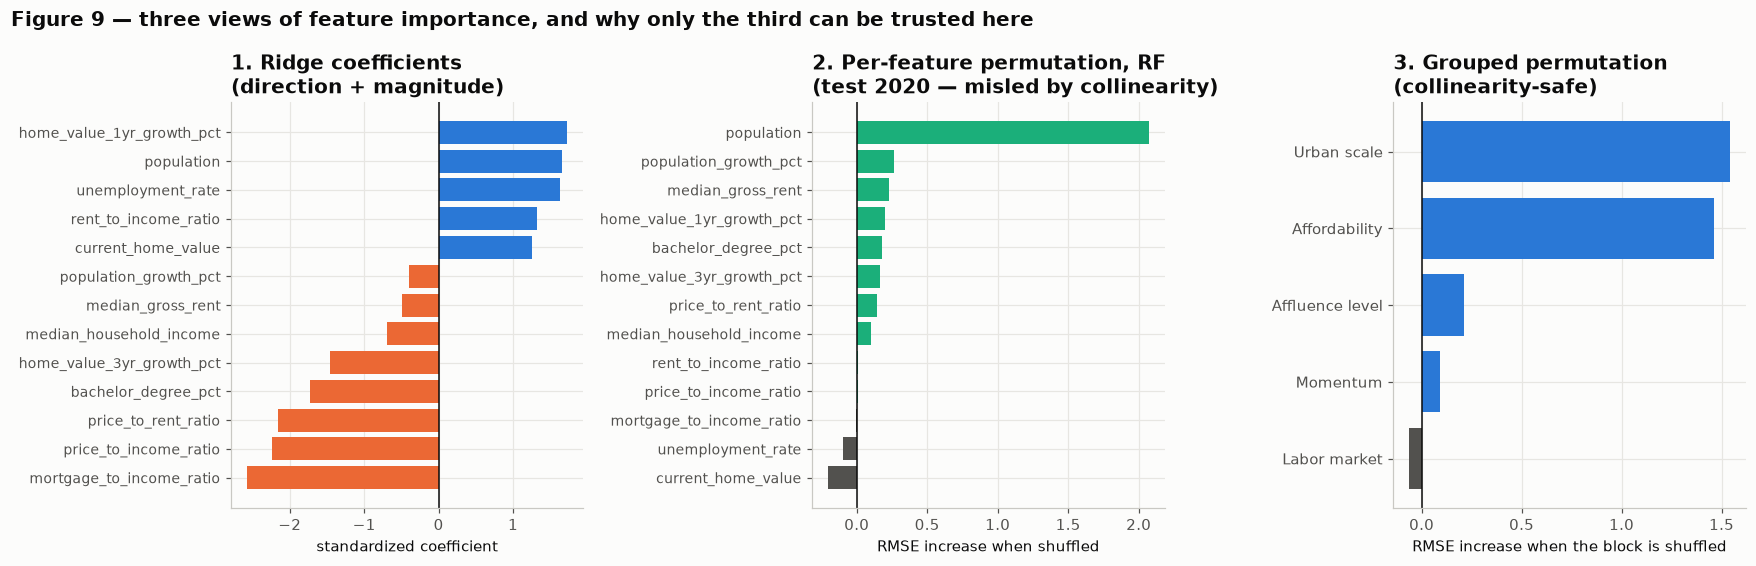

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))

ax = axes[0]
c = coefs.sort_values()
ax.barh(range(len(c)), c.values, color=[ACCENT if v < 0 else BLUE for v in c.values])
ax.set_yticks(range(len(c))); ax.set_yticklabels(c.index, fontsize=9)
ax.axvline(0, color="#0b0b0b", lw=1)
ax.set_xlabel("standardized coefficient")
ax.set_title("1. Ridge coefficients\n(direction + magnitude)")

ax = axes[1]
p = perm_rf.sort_values()
ax.barh(range(len(p)), p.values, color=[GRAY if v < 0 else GREEN for v in p.values])
ax.set_yticks(range(len(p))); ax.set_yticklabels(p.index, fontsize=9)
ax.axvline(0, color="#0b0b0b", lw=1)
ax.set_xlabel("RMSE increase when shuffled")
ax.set_title("2. Per-feature permutation, RF\n(test 2020 — misled by collinearity)")

ax = axes[2]
g = grouped["mean"].sort_values()
ax.barh(range(len(g)), g.values, color=[GRAY if v < 0 else BLUE for v in g.values])
ax.set_yticks(range(len(g))); ax.set_yticklabels(g.index, fontsize=10)
ax.axvline(0, color="#0b0b0b", lw=1)
ax.set_xlabel("RMSE increase when the block is shuffled")
ax.set_title("3. Grouped permutation\n(collinearity-safe)")

fig.suptitle("Figure 9 — three views of feature importance, and why only the third can be trusted here",
             x=0.005, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "fig09_feature_importance")
plt.show()

## 4.5 `mortgage_rate` is a base-year index in disguise

An impurity-importance chart ranks `mortgage_rate` near the top. That ranking is an artifact: the
rate is **constant within any single base year**, so inside the test year it can carry exactly zero
information about which ZIP code outgrew which. The tree gains come from using it as a year label.

This is worth demonstrating rather than asserting, because it is the most plausible way this
project could have produced a confident, wrong headline: *"interest rates are the #1 driver of ZIP
code growth."*

In [20]:
print(f"distinct mortgage_rate values in the test year: {test['mortgage_rate'].nunique()}")
pi_rate = permutation_importance(fitted["Random Forest"], X_test, y_test, n_repeats=20,
                                 random_state=RANDOM_STATE,
                                 scoring="neg_root_mean_squared_error")
rate_perm = pd.Series(pi_rate.importances_mean, index=FEATURES)["mortgage_rate"]
imp = pd.Series(fitted["Random Forest"].feature_importances_, index=FEATURES)

print(f"permutation importance of mortgage_rate on the test set: {rate_perm:.6f}")
print(f"RF *impurity* importance of mortgage_rate:  {imp['mortgage_rate']:.3f}"
      f"   (rank {int(imp.rank(ascending=False)['mortgage_rate'])} of {len(FEATURES)})")
print("\n-> ranked near the top by impurity, worth literally nothing out of sample.")

distinct mortgage_rate values in the test year: 1


permutation importance of mortgage_rate on the test set: 0.000000
RF *impurity* importance of mortgage_rate:  0.140   (rank 2 of 15)

-> ranked near the top by impurity, worth literally nothing out of sample.


---
# 5. Classification — can high-growth ZIP codes be identified in advance?

## 5.1 The label, and one leakage trap worth naming

The label is **top-quartile five-year growth**. The threshold is computed from the **training years
only**. Computing it on the full dataset would let the test rows' own outcomes help define the
boundary between "high" and "normal" — a quiet form of leakage that is easy to miss because no
feature column is involved.

In [21]:
CLF_FEATURES = [
    "current_home_value", "home_value_1yr_growth_pct", "home_value_3yr_growth_pct",
    "median_household_income", "median_gross_rent", "population", "population_growth_pct",
    "unemployment_rate", "bachelor_degree_pct", "price_to_income_ratio", "price_to_rent_ratio",
]
assert not any(c in CLF_FEATURES for c in LEAKY)
assert "mortgage_rate" not in CLF_FEATURES, "mortgage_rate is a base_year proxy (section 4.5)"

is_train = panel["base_year"].isin(TRAIN_YEARS)
thr_train = panel.loc[is_train, TARGET].quantile(0.75)
thr_full  = panel[TARGET].quantile(0.75)

panel["high_growth"] = (panel[TARGET] >= thr_train).astype(int)
panel["high_growth_rel"] = panel.groupby("base_year")[TARGET].transform(
    lambda s: (s >= s.quantile(0.75)).astype(int))

n_moved = int(((panel[TARGET] >= thr_full) != (panel[TARGET] >= thr_train)).sum())
print(f"TRAIN-ONLY 75th percentile : {thr_train:.3f}%   <- used")
print(f"FULL-DATA  75th percentile : {thr_full:.3f}%   <- would have leaked")
print(f"rows whose label the leak would have flipped: {n_moved:,} of {len(panel):,} ({n_moved/len(panel):.1%})")

prev = panel.groupby("base_year").agg(
    n=("zip_code", "size"), mean_growth=(TARGET, "mean"),
    absolute_label_rate=("high_growth", "mean"), absolute_label_n=("high_growth", "sum"),
    within_year_label_rate=("high_growth_rel", "mean"))
print()
print(prev.round(4).to_string())

TRAIN-ONLY 75th percentile : 58.676%   <- used
FULL-DATA  75th percentile : 54.080%   <- would have leaked
rows whose label the leak would have flipped: 572 of 7,487 (7.6%)

              n  mean_growth  absolute_label_rate  absolute_label_n  within_year_label_rate
base_year                                                                                  
2016       1452       57.929                0.426               618                   0.250
2017       1496       48.309                0.241               360                   0.250
2018       1500       37.947                0.089               134                   0.250
2019       1511       38.153                0.105               158                   0.250
2020       1528       24.312                0.020                30                   0.250


## 5.2 The consequence: the positive class evaporates

With a **fixed** threshold and a **moving** distribution, the share of "high-growth" ZIP codes
collapses from **42.6% in 2016 to 2.0% in 2020** — 30 positives out of 1,528 rows. This is the §4
regime shift reappearing in classification form.

Two things follow immediately:

1. A majority-class baseline scores **98.04% accuracy** on the test year by predicting that no ZIP
   code is ever high-growth. **Accuracy is therefore not used as a headline metric anywhere in this
   project.** Two dummy classifiers are kept in every table specifically so the reader can see this
   number and discount it.
2. Any F1 computed against 30 positives is dominated by the class collapse, not by model quality.

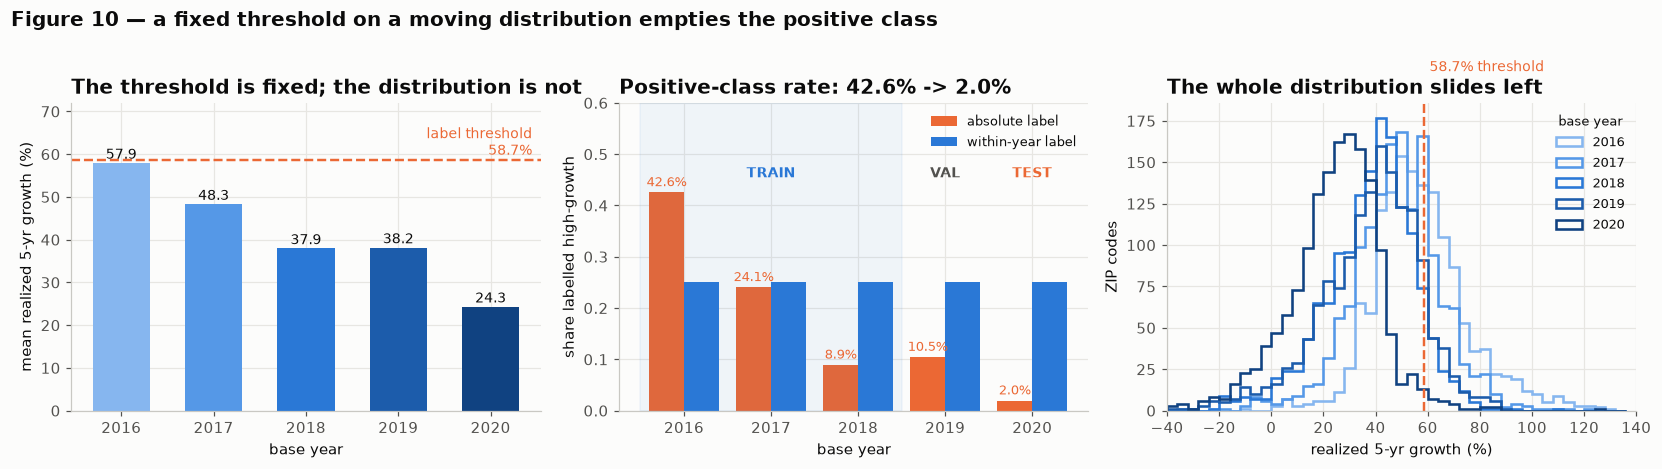

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
yrs = prev.index.astype(str)

ax = axes[0]
ax.bar(yrs, prev["mean_growth"], color=YEAR_COLORS, width=0.62)
ax.axhline(thr_train, color=ACCENT, lw=1.6, ls="--")
ax.text(4.45, thr_train + 1.2, f"label threshold\n{thr_train:.1f}%", color=ACCENT,
        fontsize=9, ha="right")
for i, v in enumerate(prev["mean_growth"]):
    ax.text(i, v + 1.0, f"{v:.1f}", ha="center", fontsize=9)
ax.set_ylim(0, 72)
ax.set_title("The threshold is fixed; the distribution is not")
ax.set_xlabel("base year"); ax.set_ylabel("mean realized 5-yr growth (%)")

ax = axes[1]
ax.bar(np.arange(5) - 0.2, prev["absolute_label_rate"], 0.4, color=ACCENT, label="absolute label")
ax.bar(np.arange(5) + 0.2, prev["within_year_label_rate"], 0.4, color=BLUE, label="within-year label")
for i, v in enumerate(prev["absolute_label_rate"]):
    ax.text(i - 0.2, v + 0.012, f"{v:.1%}", ha="center", fontsize=8.5, color=ACCENT)
ax.axvspan(-0.5, 2.5, color=BLUE, alpha=0.06)
ax.text(1.0, 0.455, "TRAIN", ha="center", color=BLUE, fontweight="bold", fontsize=9)
ax.text(3.0, 0.455, "VAL", ha="center", color=GRAY, fontweight="bold", fontsize=9)
ax.text(4.0, 0.455, "TEST", ha="center", color=ACCENT, fontweight="bold", fontsize=9)
ax.set_xticks(range(5)); ax.set_xticklabels(yrs)
ax.set_ylim(0, 0.60)
ax.set_title("Positive-class rate: 42.6% -> 2.0%")
ax.set_xlabel("base year"); ax.set_ylabel("share labelled high-growth")
ax.legend(fontsize=8.5, loc="upper right")

ax = axes[2]
for (y, g), c in zip(panel.groupby("base_year"), YEAR_COLORS):
    ax.hist(g[TARGET], bins=np.arange(-40, 140, 4), histtype="step", lw=1.7, color=c, label=str(y))
ax.axvline(thr_train, color=ACCENT, lw=1.6, ls="--")
ax.text(thr_train + 2, 205, f"{thr_train:.1f}% threshold", color=ACCENT, fontsize=9)
ax.set_xlim(-40, 140)
ax.set_title("The whole distribution slides left")
ax.set_xlabel("realized 5-yr growth (%)"); ax.set_ylabel("ZIP codes")
ax.legend(fontsize=8.5, title="base year", title_fontsize=8.5)

fig.suptitle("Figure 10 — a fixed threshold on a moving distribution empties the positive class",
             x=0.005, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "fig10_label_prevalence")
plt.show()

## 5.3 Six models, both label definitions

Six models — two dummy baselines, logistic regression, a decision tree, an untuned Random Forest,
and a Random Forest tuned by `GridSearchCV` over 36 parameter combinations, **scored on F1 rather
than accuracy** for the reason above. Cross-validation is `GroupKFold` on `base_year` throughout.

Both label definitions are fitted so the comparison is like-for-like: same features, same rows,
same folds, only the label changes.

In [23]:
PARAM_GRID = {"n_estimators": [100, 200], "max_depth": [5, 10, None],
              "min_samples_leaf": [1, 3, 5], "class_weight": [None, "balanced"]}

def clf_roster(rf_params=None):
    rf_params = rf_params or {"n_estimators": 300}
    return {
        "Majority baseline":   DummyClassifier(strategy="most_frequent"),
        "Stratified baseline": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
        "Logistic Regression": Pipeline([("scaler", StandardScaler()),
                                         ("model", LogisticRegression(max_iter=2000,
                                                                      class_weight="balanced",
                                                                      random_state=RANDOM_STATE))]),
        "Decision Tree": DecisionTreeClassifier(max_depth=4, min_samples_leaf=20,
                                                class_weight="balanced", random_state=RANDOM_STATE),
        "Random Forest (default)": RandomForestClassifier(n_estimators=300,
                                                          random_state=RANDOM_STATE, n_jobs=-1),
        "Random Forest (tuned)": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1,
                                                        **rf_params),
    }

def scores(model, X, y):
    pred, prob = model.predict(X), model.predict_proba(X)[:, 1]
    return {"Accuracy": accuracy_score(y, pred),
            "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y, prob) if y.nunique() > 1 else np.nan,
            "Avg prec.": average_precision_score(y, prob),
            "n flagged": int(pred.sum())}

def run_label(label):
    tr, va, te = panel[is_train], panel[panel.base_year == VAL_YEAR], panel[panel.base_year == TEST_YEAR]
    Xtr, ytr = tr[CLF_FEATURES], tr[label]
    Xva, yva = va[CLF_FEATURES], va[label]
    Xte, yte = te[CLF_FEATURES], te[label]
    gs = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                      PARAM_GRID, scoring="f1", cv=GroupKFold(n_splits=3), n_jobs=-1)
    gs.fit(Xtr, ytr, groups=tr["base_year"])
    fits, res = {}, {}
    for name, m in clf_roster(gs.best_params_).items():
        m.fit(Xtr, ytr)
        fits[name] = m
        res[name] = {"val": scores(m, Xva, yva), "test": scores(m, Xte, yte)}
    order = list(clf_roster())
    return {"gs": gs, "fitted": fits,
            "val": pd.DataFrame({n: res[n]["val"] for n in order}).T,
            "test": pd.DataFrame({n: res[n]["test"] for n in order}).T,
            "X": (Xtr, Xva, Xte), "y": (ytr, yva, yte)}

runs = {}
for label, tag in [("high_growth", "absolute"), ("high_growth_rel", "within-year")]:
    runs[tag] = run_label(label)
    r = runs[tag]
    print(f"[{tag} label]  best CV F1 {r['gs'].best_score_:.4f}  params {r['gs'].best_params_}")
    print(f"  positive rate  train {r['y'][0].mean():.3f}  val {r['y'][1].mean():.3f}"
          f"  test {r['y'][2].mean():.3f}")
    print(f"\n  TEST (2020)")
    print("  " + r["test"].round(4).to_string().replace("\n", "\n  "))
    print()

/Users/chestnut/Cumberlands/BigData&DataMining/house_price/Project/Deliverable1/venv-Project/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/chestnut/Cumberlands/BigData&DataMining/house_price/Project/Deliverable1/venv-Project/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/chestnut/Cumberlands/BigData&DataMining/house_price/Project/Deliverable1/venv-Project/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel

/Users/chestnut/Cumberlands/BigData&DataMining/house_price/Project/Deliverable1/venv-Project/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/chestnut/Cumberlands/BigData&DataMining/house_price/Project/Deliverable1/venv-Project/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/chestnut/Cumberlands/BigData&DataMining/house_price/Project/Deliverable1/venv-Project/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel

/Users/chestnut/Cumberlands/BigData&DataMining/house_price/Project/Deliverable1/venv-Project/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/chestnut/Cumberlands/BigData&DataMining/house_price/Project/Deliverable1/venv-Project/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/chestnut/Cumberlands/BigData&DataMining/house_price/Project/Deliverable1/venv-Project/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel

/Users/chestnut/Cumberlands/BigData&DataMining/house_price/Project/Deliverable1/venv-Project/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/chestnut/Cumberlands/BigData&DataMining/house_price/Project/Deliverable1/venv-Project/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/chestnut/Cumberlands/BigData&DataMining/house_price/Project/Deliverable1/venv-Project/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel

[absolute label]  best CV F1 0.4658  params {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 100}
  positive rate  train 0.250  val 0.105  test 0.020

  TEST (2020)
                           Accuracy  Precision  Recall    F1  ROC-AUC  Avg prec.  n flagged
  Majority baseline           0.980      0.000   0.000 0.000    0.500      0.020      0.000
  Stratified baseline         0.737      0.018   0.233 0.034    0.490      0.019    386.000
  Logistic Regression         0.670      0.012   0.200 0.023    0.470      0.018    486.000
  Decision Tree               0.546      0.042   1.000 0.080    0.719      0.040    723.000
  Random Forest (default)     0.925      0.071   0.233 0.109    0.799      0.069     98.000
  Random Forest (tuned)       0.840      0.050   0.400 0.089    0.793      0.053    239.000



[within-year label]  best CV F1 0.5137  params {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 100}
  positive rate  train 0.250  val 0.250  test 0.250

  TEST (2020)
                           Accuracy  Precision  Recall    F1  ROC-AUC  Avg prec.  n flagged
  Majority baseline           0.750      0.000   0.000 0.000    0.500      0.250      0.000
  Stratified baseline         0.610      0.223   0.225 0.224    0.482      0.244    386.000
  Logistic Regression         0.641      0.361   0.563 0.440    0.649      0.376    596.000
  Decision Tree               0.679      0.361   0.369 0.365    0.650      0.365    391.000
  Random Forest (default)     0.762      0.578   0.175 0.269    0.693      0.448    116.000
  Random Forest (tuned)       0.747      0.491   0.345 0.406    0.719      0.456    269.000



## 5.4 The diagnosis: ranking survives, calibration does not

Under the **absolute** label the tuned Random Forest posts test F1 = 0.089 and test ROC-AUC =
0.793 — *higher* than its validation AUC. These are not contradictory. They measure different
things:

- The model's **mean predicted probability** on the test year is ≈ 0.31 while the actual positive
  rate is 0.020 — miscalibrated by roughly a factor of sixteen.
- Its **ordering** is still informative: the top-30 ranked ZIP codes contain about 3.4× their
  expected share of true positives, and the bottom five deciles contain none of the 30 positives.

Sweeping the decision threshold across its entire range never lifts test F1 above ≈ 0.13, so the
problem is not a badly chosen cutoff — it is that the class itself has almost disappeared.

Under the **within-year** label, prevalence is pinned at 25% in every year by construction and the
question becomes *"will this ZIP code finish in the top quarter for its own period?"* Test F1 for
the tuned Random Forest rises from **0.089 → 0.406**, and logistic regression from 0.023 → 0.440.
Test ROC-AUC falls slightly (0.793 → 0.719) because separating the top-quartile *boundary* is a
harder ranking problem than isolating the extreme tail.

Precision on the test year is ≈ 0.49: **about half of the ZIP codes the model flags are wrong.**
Fixing the label removed the level shift; it did not make five-year housing outcomes easy.

In [24]:
def ranking_report(model, X, y, tag):
    prob = model.predict_proba(X)[:, 1]
    n_pos = int(y.sum())
    hits = int(y.values[np.argsort(-prob)[:n_pos]].sum())
    base = y.mean()
    dec = pd.DataFrame({"decile": pd.qcut(pd.Series(prob).rank(method="first"), 10, labels=False),
                        "y": y.values}).groupby("decile")["y"].mean()
    return {"tag": tag, "prevalence": base, "mean predicted prob": prob.mean(),
            "ROC-AUC": roc_auc_score(y, prob), "precision @ top-k": hits / n_pos,
            "lift @ top-k": (hits / n_pos) / base,
            "top-decile lift": dec.iloc[-1] / base,
            "bottom-decile hit rate": dec.iloc[0]}, dec

rep = []
decs = {}
for tag in ["absolute", "within-year"]:
    r = runs[tag]
    m = r["fitted"]["Random Forest (tuned)"]
    a, dv = ranking_report(m, r["X"][1], r["y"][1], f"{tag} · val 2019")
    b, dt = ranking_report(m, r["X"][2], r["y"][2], f"{tag} · test 2020")
    rep += [a, b]
    decs[tag] = (dv, dt, r["y"][1].mean(), r["y"][2].mean())
print(pd.DataFrame(rep).set_index("tag").T.round(4).to_string())

tag                     absolute · val 2019  absolute · test 2020  within-year · val 2019  within-year · test 2020
prevalence                            0.105                 0.020                   0.250                    0.250
mean predicted prob                   0.344                 0.311                   0.426                    0.365
ROC-AUC                               0.759                 0.793                   0.780                    0.719
precision @ top-k                     0.310                 0.067                   0.521                    0.463
lift @ top-k                          2.966                 3.396                   2.083                    1.853
top-decile lift                       3.040                 2.663                   2.647                    2.144
bottom-decile hit rate                0.007                 0.000                   0.040                    0.078


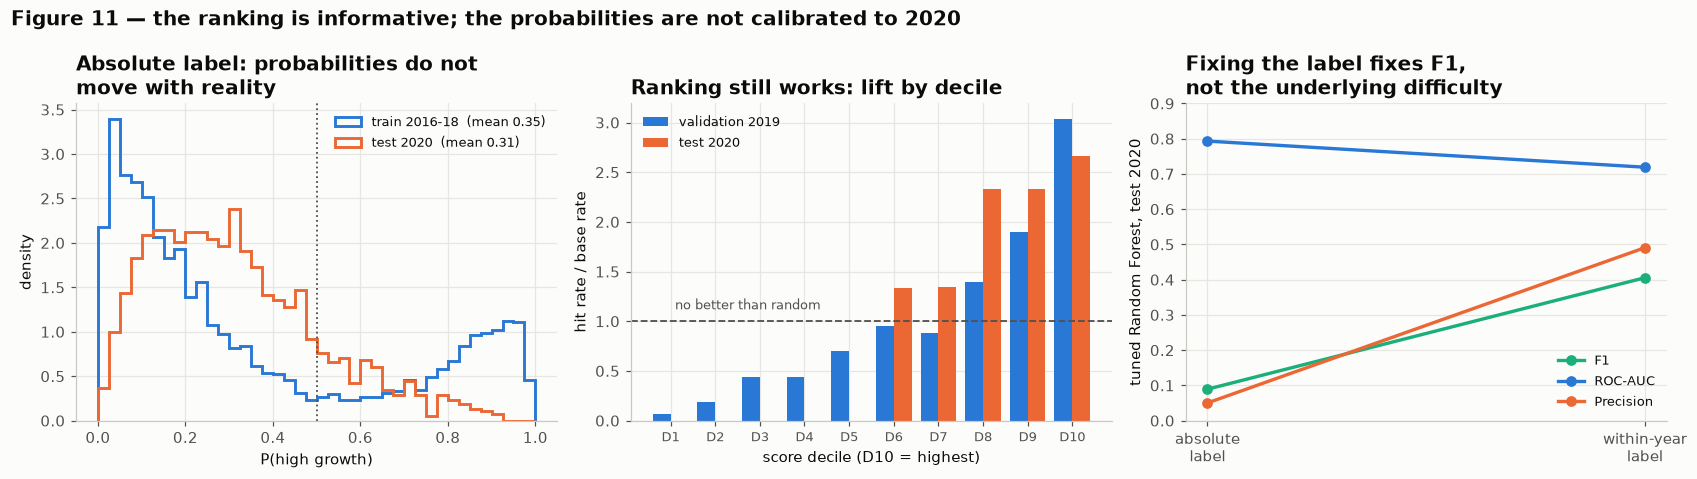

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))
ra, rr = runs["absolute"], runs["within-year"]

ax = axes[0]
m = ra["fitted"]["Random Forest (tuned)"]
for X, y, tag, c in [(ra["X"][0], ra["y"][0], "train 2016-18", BLUE),
                     (ra["X"][2], ra["y"][2], "test 2020", ACCENT)]:
    prob = m.predict_proba(X)[:, 1]
    ax.hist(prob, bins=np.linspace(0, 1, 41), density=True, histtype="step", lw=1.9,
            color=c, label=f"{tag}  (mean {prob.mean():.2f})")
ax.axvline(0.5, color=GRAY, lw=1.2, ls=":")
ax.set_title("Absolute label: probabilities do not\nmove with reality")
ax.set_xlabel("P(high growth)"); ax.set_ylabel("density")
ax.legend(fontsize=8.5)

ax = axes[1]
dv, dt, bv, bt = decs["absolute"]
xs = np.arange(10)
ax.bar(xs - 0.2, dv / bv, 0.4, color=BLUE, label="validation 2019")
ax.bar(xs + 0.2, dt / bt, 0.4, color=ACCENT, label="test 2020")
ax.axhline(1.0, color=GRAY, lw=1.2, ls="--")
ax.text(0.1, 1.12, "no better than random", color=GRAY, fontsize=8.5)
ax.set_xticks(xs); ax.set_xticklabels([f"D{i+1}" for i in xs], fontsize=8.5)
ax.set_xlabel("score decile (D10 = highest)"); ax.set_ylabel("hit rate / base rate")
ax.set_title("Ranking still works: lift by decile")
ax.legend(fontsize=8.5)

ax = axes[2]
for met, c in [("F1", GREEN), ("ROC-AUC", BLUE), ("Precision", ACCENT)]:
    ax.plot([0, 1], [ra["test"].loc["Random Forest (tuned)", met],
                     rr["test"].loc["Random Forest (tuned)", met]],
            marker="o", lw=2.2, color=c, label=met)
ax.set_xticks([0, 1]); ax.set_xticklabels(["absolute\nlabel", "within-year\nlabel"], fontsize=9.5)
ax.set_ylim(0, 0.9)
ax.set_ylabel("tuned Random Forest, test 2020")
ax.set_title("Fixing the label fixes F1,\nnot the underlying difficulty")
ax.legend(fontsize=8.5)

fig.suptitle("Figure 11 — the ranking is informative; the probabilities are not calibrated to 2020",
             x=0.005, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "fig11_ranking_vs_calibration")
plt.show()

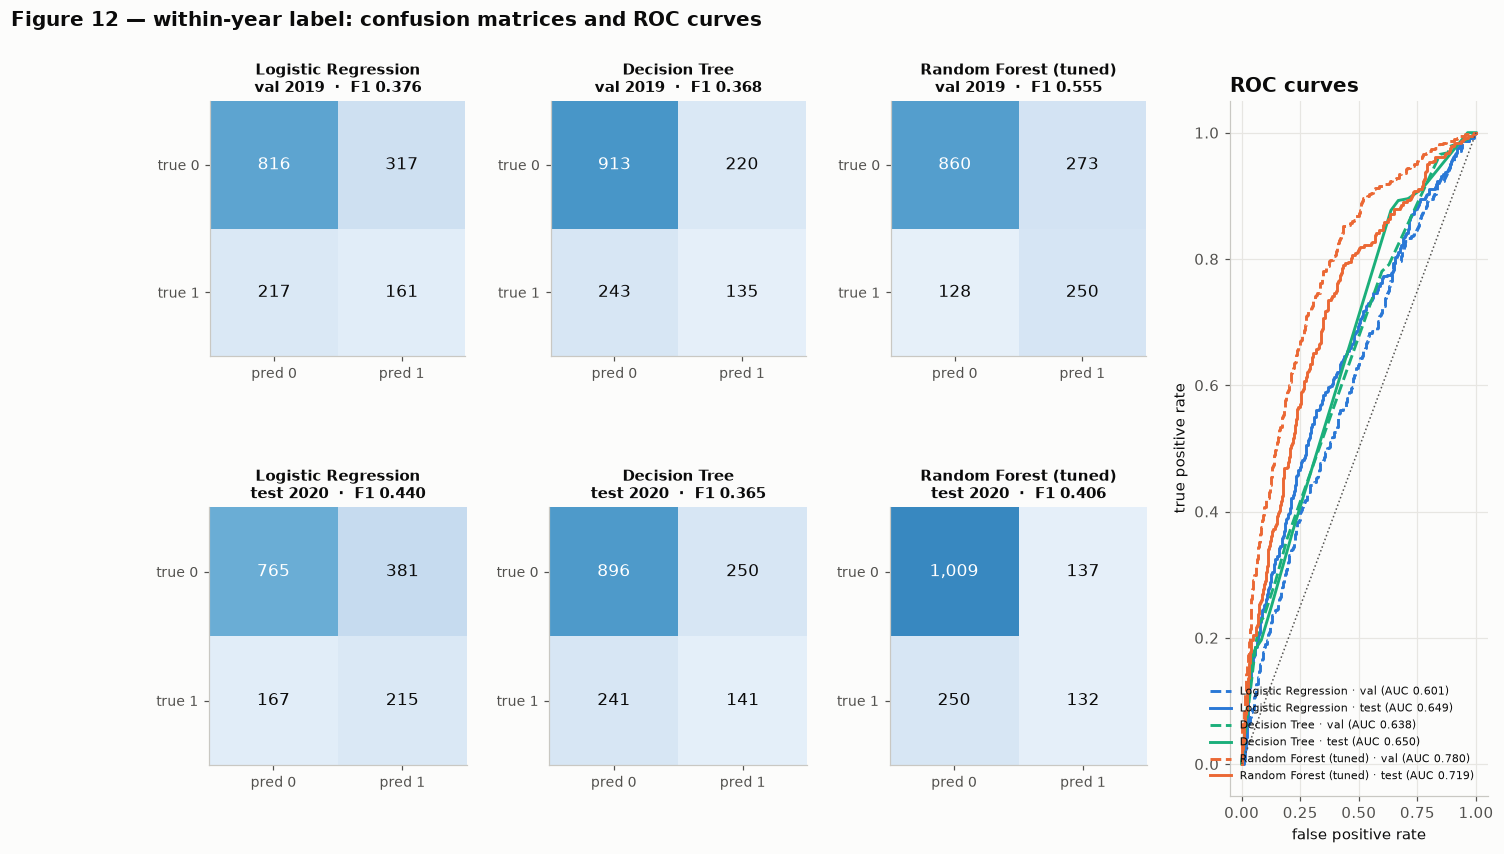

In [26]:
# Confusion matrices and ROC curves, within-year label -- the configuration actually recommended.
Xr_va, yr_va = rr["X"][1], rr["y"][1]
Xr_te, yr_te = rr["X"][2], rr["y"][2]
names = ["Logistic Regression", "Decision Tree", "Random Forest (tuned)"]

fig = plt.figure(figsize=(15, 8.2))
gsx = fig.add_gridspec(2, 4, height_ratios=[1, 1.25], hspace=0.42, wspace=0.32)
for j, name in enumerate(names):
    for i, (X, y, tag) in enumerate([(Xr_va, yr_va, "val 2019"), (Xr_te, yr_te, "test 2020")]):
        ax = fig.add_subplot(gsx[i, j])
        cm = confusion_matrix(y, rr["fitted"][name].predict(X))
        ax.imshow(cm / cm.sum(), cmap="Blues", vmin=0, vmax=1)
        for r_ in range(2):
            for c_ in range(2):
                ax.text(c_, r_, f"{cm[r_, c_]:,}", ha="center", va="center", fontsize=11,
                        color="white" if cm[r_, c_] / cm.sum() > 0.5 else "#0b0b0b")
        ax.set_xticks([0, 1]); ax.set_xticklabels(["pred 0", "pred 1"], fontsize=9)
        ax.set_yticks([0, 1]); ax.set_yticklabels(["true 0", "true 1"], fontsize=9)
        ax.grid(False)
        ax.set_title(f"{name}\n{tag}  ·  F1 {f1_score(y, rr['fitted'][name].predict(X)):.3f}",
                     fontsize=9.5, loc="center")

ax = fig.add_subplot(gsx[:, 3])
for name, c in zip(names, [BLUE, GREEN, ACCENT]):
    for (X, y, tag), ls in [((Xr_va, yr_va, "val"), "--"), ((Xr_te, yr_te, "test"), "-")]:
        prob = rr["fitted"][name].predict_proba(X)[:, 1]
        fpr, tpr, _ = roc_curve(y, prob)
        ax.plot(fpr, tpr, ls, color=c, lw=1.9,
                label=f"{name} · {tag} (AUC {roc_auc_score(y, prob):.3f})")
ax.plot([0, 1], [0, 1], color=GRAY, lw=1, ls=":")
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.set_title("ROC curves")
ax.legend(fontsize=7.0, loc="lower right", borderaxespad=0.9)

fig.suptitle("Figure 12 — within-year label: confusion matrices and ROC curves",
             x=0.005, ha="left", fontweight="bold", fontsize=13)
save(fig, "fig12_confusion_roc")
plt.show()

In [27]:
lr = rr["fitted"]["Logistic Regression"]
lr_coefs = pd.Series(lr.named_steps["model"].coef_[0], index=CLF_FEATURES).sort_values()
print("Logistic Regression -- standardized coefficients and odds ratios per +1 SD")
print(pd.DataFrame({"coefficient": lr_coefs, "odds ratio": np.exp(lr_coefs)}).round(3).to_string())
print(f"\nThe largest stable negative coefficient is price_to_rent_ratio: "
      f"odds ratio {np.exp(lr_coefs['price_to_rent_ratio']):.3f} per +1 SD.")
print("The largest positive is current_home_value -- but see section 4.4: under this collinearity")
print("a single large positive coefficient offsets the negative affordability terms it is paired")
print("with, so it should be read as part of the affluence block, not as a standalone driver.")

print("\nWhich hyperparameter actually mattered? mean CV F1 by class_weight:")
for tag in ["absolute", "within-year"]:
    cv = pd.DataFrame(runs[tag]["gs"].cv_results_)
    cv["class_weight"] = np.where(cv["param_class_weight"].isna(), "None", "balanced")
    print(f"  [{tag} label] "
          + "   ".join(f"{k}: {v:.4f}"
                       for k, v in cv.groupby("class_weight")["mean_test_score"].mean().items()))
print("  -> a single setting, not the tree geometry, is what the grid search actually bought.")

Logistic Regression -- standardized coefficients and odds ratios per +1 SD
                           coefficient  odds ratio
price_to_rent_ratio             -1.574       0.207
median_household_income         -0.669       0.512
median_gross_rent               -0.350       0.705
home_value_3yr_growth_pct       -0.332       0.718
price_to_income_ratio           -0.314       0.731
bachelor_degree_pct             -0.106       0.900
population_growth_pct            0.006       1.006
home_value_1yr_growth_pct        0.108       1.114
population                       0.212       1.237
unemployment_rate                0.249       1.283
current_home_value               1.851       6.366

The largest stable negative coefficient is price_to_rent_ratio: odds ratio 0.207 per +1 SD.
The largest positive is current_home_value -- but see section 4.4: under this collinearity
a single large positive coefficient offsets the negative affordability terms it is paired
with, so it should be read as part of t

---
# 6. Clustering — what types of housing market does California contain?

Segmentation, not prediction, so **the outcome variable is excluded from the feature set** —
clustering on the target would be circular. Seven descriptive features are used.

Three design decisions:

- **Only the 2020 slice is clustered**, so each ZIP code appears exactly once. Clustering the full
  panel would place five near-identical copies of every ZIP in the same space and distort the
  geometry.
- **Standardization is mandatory.** Home values are on the order of 10⁶ and unemployment on the
  order of 10¹; without scaling, K-Means would simply sort ZIP codes by price.
- **Winsorize at the 1st/99th percentile.** A handful of ZIP codes report population growth above
  500%, which reflects Census boundary changes rather than housing markets. A single extreme point
  can capture an entire cluster.

In [28]:
CLUSTER_FEATURES = ["current_home_value", "median_gross_rent", "median_household_income",
                    "price_to_income_ratio", "unemployment_rate", "population_growth_pct",
                    "bachelor_degree_pct"]
assert TARGET not in CLUSTER_FEATURES, "clustering on the outcome would be circular"

snap = panel[panel.base_year == TEST_YEAR].copy()
print(f"2020 slice: {len(snap):,} ZIP codes, one row each "
      f"(duplicate zip_codes: {snap.zip_code.duplicated().sum()})")
print("\nwhy winsorizing is needed -- population_growth_pct extremes:")
print(snap.nlargest(4, "population_growth_pct")[
    ["zip_code", "city", "county", "population", "population_growth_pct"]].to_string(index=False))

lo_q, hi_q = snap[CLUSTER_FEATURES].quantile(0.01), snap[CLUSTER_FEATURES].quantile(0.99)
Cw = snap[CLUSTER_FEATURES].clip(lo_q, hi_q, axis=1)
scaler_c = StandardScaler().fit(Cw)
Xc = scaler_c.transform(Cw)
print(f"\nscaled matrix {Xc.shape}   column means ~{np.abs(Xc.mean(0)).max():.1e}"
      f"   column sds ~{Xc.std(0).mean():.3f}")

rows = []
for k in range(2, 11):
    km_ = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(Xc)
    rows.append({"k": k, "inertia": km_.inertia_,
                 "silhouette": silhouette_score(Xc, km_.labels_),
                 "Calinski-Harabasz": calinski_harabasz_score(Xc, km_.labels_),
                 "Davies-Bouldin": davies_bouldin_score(Xc, km_.labels_),
                 "smallest cluster": pd.Series(km_.labels_).value_counts().min()})
kdiag = pd.DataFrame(rows).set_index("k")
kdiag["inertia drop %"] = -kdiag["inertia"].pct_change() * 100
print()
print(kdiag.round(4).to_string())

2020 slice: 1,528 ZIP codes, one row each (duplicate zip_codes: 0)

why winsorizing is needed -- population_growth_pct extremes:
zip_code             city           county  population  population_growth_pct
   96105              NaN    Sierra County     351.000                646.809
   92060 Palomar Mountain San Diego County     457.000                572.059
   96126      Sierraville    Sierra County     166.000                201.818
   91934          Jacumba San Diego County     785.000                194.007

scaled matrix (1528, 7)   column means ~3.3e-16   column sds ~1.000



     inertia  silhouette  Calinski-Harabasz  Davies-Bouldin  smallest cluster  inertia drop %
k                                                                                            
2  6,987.343       0.336            809.952           1.177               532             NaN
3  5,898.062       0.228            620.285           1.400               305          15.589
4  5,223.207       0.227            532.274           1.375               143          11.442
5  4,632.876       0.228            498.294           1.282               120          11.302
6  4,184.125       0.227            473.752           1.216                52           9.686
7  3,857.636       0.252            449.375           1.195                51           7.803
8  3,558.312       0.213            435.571           1.227                46           7.759
9  3,346.727       0.197            416.959           1.268                44           5.946
10 3,140.759       0.200            405.737           1.225

### Choosing k when the criteria disagree

The elbow suggests **k = 3**; the silhouette peaks at **k = 2**. But k = 2 only separates expensive
from inexpensive markets and carries no usable information, and the silhouette scores for k = 3…6
differ by **0.0014** — the metric cannot distinguish between them.

The tie-break was therefore **stated in advance**: *choose the smallest k at which clusters are
distinguished by different features rather than by a single affluence gradient.* At k = 3 the
clusters form a ladder in which every feature rises together. At **k = 5**, two clusters break that
pattern — one with an extreme price-to-income ratio but ordinary income, one with high unemployment
and high population growth. That is the segmentation reported.

The mean silhouette of ≈ 0.23 is low, and this is stated rather than buried: **California ZIP codes
lie along a continuum, not in well-separated groups.** The clusters are a useful description, not a
discovery of natural kinds.

In [29]:
K_CHOSEN = 5
km = KMeans(n_clusters=K_CHOSEN, random_state=RANDOM_STATE, n_init=10).fit(Xc)
snap["cluster"] = km.labels_

profile = snap.groupby("cluster")[CLUSTER_FEATURES].mean()
profile.insert(0, "n", snap["cluster"].value_counts().sort_index())
profile["mean 5yr growth"] = snap.groupby("cluster")[TARGET].mean()

# Identify each cluster by its defining trait, so names never depend on K-Means' label numbering.
p_ = profile[CLUSTER_FEATURES]
id_elite     = p_["current_home_value"].idxmax()
id_stretched = p_["price_to_income_ratio"].idxmax()
id_working   = p_["unemployment_rate"].idxmax()
rest = [c for c in p_.index if c not in {id_elite, id_stretched, id_working}]
id_affluent  = p_.loc[rest, "bachelor_degree_pct"].idxmax()
id_midmarket = [c for c in rest if c != id_affluent][0]

NAMES = {id_elite: "Elite Coastal & Tech Markets",
         id_affluent: "Affluent Growing Suburbs",
         id_midmarket: "Mid-Market Suburban California",
         id_stretched: "Price-Detached Urban Markets",
         id_working: "Affordable Working-Class Markets"}
assert len(set(NAMES.values())) == K_CHOSEN, "cluster naming rules collided"
snap["segment"] = snap["cluster"].map(NAMES)

print("Cluster profile -- raw feature means (2020 slice)")
print(profile.rename(index=NAMES).round(2).to_string())

for c in sorted(NAMES):
    s = snap[snap.cluster == c]
    print(f"\n{NAMES[c]}  (n={len(s)})")
    print(f"  median value ${s.current_home_value.median():>10,.0f} | "
          f"income ${s.median_household_income.median():>8,.0f} | "
          f"P/I {s.price_to_income_ratio.median():>5.1f} | "
          f"unemp {s.unemployment_rate.median():>5.1f}% | "
          f"BA {s.bachelor_degree_pct.median():>5.1f}%")
    print(f"  counties: {', '.join(f'{k} ({v})' for k, v in s.county.value_counts().head(4).items())}")
    print(f"  largest ZIPs: {', '.join(f'{r.zip_code} {r.city}' for r in s.nlargest(4, 'population')[['zip_code','city']].itertuples())}")

Cluster profile -- raw feature means (2020 slice)
                                    n  current_home_value  median_gross_rent  median_household_income  price_to_income_ratio  unemployment_rate  population_growth_pct  bachelor_degree_pct  mean 5yr growth
cluster                                                                                                                                                                                                     
Mid-Market Suburban California    659         471,638.690          1,360.060               67,991.880                  7.090              5.410                 -0.100               23.590           23.320
Elite Coastal & Tech Markets      120       1,947,252.370          2,621.380              161,442.300                 12.220              3.960                  3.140               71.050           26.660
Affluent Growing Suburbs          366         856,171.220          2,009.470              108,297.550                  8.070      

PC1 + PC2 retain 69.3% of the variance in the 7 scaled features

                           PC1    PC2
current_home_value       0.476  0.218
median_gross_rent        0.455 -0.210
median_household_income  0.454 -0.309
price_to_income_ratio    0.264  0.641
unemployment_rate       -0.268  0.049
population_growth_pct    0.015 -0.632
bachelor_degree_pct      0.468 -0.031


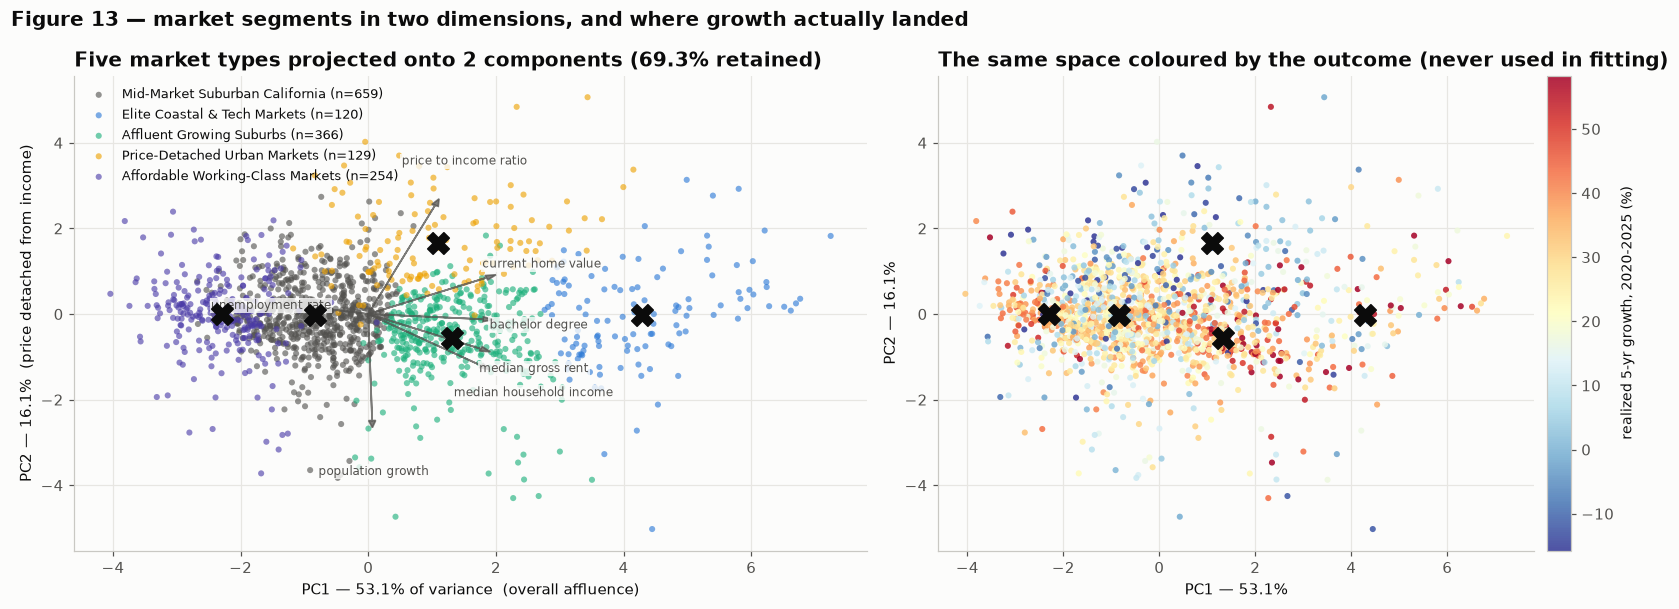

In [30]:
pca = PCA(n_components=len(CLUSTER_FEATURES), random_state=RANDOM_STATE).fit(Xc)
XY = pca.transform(Xc)
evr = pca.explained_variance_ratio_
loadings = pd.DataFrame(pca.components_[:2].T, index=CLUSTER_FEATURES, columns=["PC1", "PC2"])
print(f"PC1 + PC2 retain {evr[:2].sum():.1%} of the variance in the 7 scaled features\n")
print(loadings.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1.25, 1]})

ax = axes[0]
for c in sorted(NAMES):
    m = snap.cluster.values == c
    ax.scatter(XY[m, 0], XY[m, 1], s=16, alpha=0.62, color=CATEGORICAL[c],
               label=f"{NAMES[c]} (n={m.sum()})", edgecolor="none")
cen = pca.transform(km.cluster_centers_)
ax.scatter(cen[:, 0], cen[:, 1], marker="X", s=200, color="#0b0b0b", zorder=6)
for f in CLUSTER_FEATURES:
    ax.arrow(0, 0, loadings.loc[f, "PC1"] * 4.2, loadings.loc[f, "PC2"] * 4.2,
             color=GRAY, lw=1.1, alpha=0.75, head_width=0.11, length_includes_head=True)
    ax.text(loadings.loc[f, "PC1"] * 5.7, loadings.loc[f, "PC2"] * 5.7 - 0.16,
            f.replace("_pct", "").replace("_", " "), fontsize=7.6, color=GRAY, ha="center",
            bbox=dict(facecolor="#fcfcfb", edgecolor="none", pad=0.9, alpha=0.8))
ax.set_xlabel(f"PC1 — {evr[0]:.1%} of variance  (overall affluence)")
ax.set_ylabel(f"PC2 — {evr[1]:.1%}  (price detached from income)")
ax.set_title(f"Five market types projected onto 2 components ({evr[:2].sum():.1%} retained)")
ax.legend(fontsize=8.4, loc="upper left")

ax = axes[1]
sc = ax.scatter(XY[:, 0], XY[:, 1], c=snap[TARGET], cmap="RdYlBu_r", s=16, alpha=0.85,
                vmin=snap[TARGET].quantile(0.02), vmax=snap[TARGET].quantile(0.98), edgecolor="none")
ax.scatter(cen[:, 0], cen[:, 1], marker="X", s=200, color="#0b0b0b", zorder=6)
cb = fig.colorbar(sc, ax=ax, fraction=0.04, pad=0.02)
cb.set_label("realized 5-yr growth, 2020-2025 (%)", fontsize=9)
ax.set_xlabel(f"PC1 — {evr[0]:.1%}"); ax.set_ylabel(f"PC2 — {evr[1]:.1%}")
ax.set_title("The same space coloured by the outcome (never used in fitting)")

fig.suptitle("Figure 13 — market segments in two dimensions, and where growth actually landed",
             x=0.005, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "fig13_pca_clusters")
plt.show()

## 6.1 Do the segments actually differ in outcome?

The segmentation never saw the outcome. Comparing against it afterwards is therefore a genuine
check, not a restatement — with one honest caveat: `price_to_income_ratio` **is** one of the seven
clustering features, so the Price-Detached result re-derives the affordability finding by an
unsupervised route rather than confirming it from independent evidence. What clustering *adds* is
that the effect is concentrated in a **specific, identifiable type of market** rather than smeared
smoothly across all ZIP codes.

Every base year is then assigned to the 2020-fitted segmentation. **The scaler and centroids are
not refitted** — each year is scored by the same rule.

In [31]:
allp = panel.copy()
allp["cluster"] = km.predict(scaler_c.transform(allp[CLUSTER_FEATURES].clip(lo_q, hi_q, axis=1)))
allp["segment"] = allp["cluster"].map(NAMES)
allp["growth_rel"] = allp[TARGET] - allp.groupby("base_year")[TARGET].transform("median")

by_year_seg = allp.pivot_table(index="segment", columns="base_year", values=TARGET, aggfunc="mean")
seg_summary = allp.groupby("segment").agg(
    n=("zip_code", "size"), mean_growth=(TARGET, "mean"),
    rel_growth_mean=("growth_rel", "mean"),
    top_quartile_rate=("high_growth_rel", "mean")).sort_values("rel_growth_mean", ascending=False)

F, p_anova = stats.f_oneway(*[g[TARGET].values for _, g in snap.groupby("cluster")])
H = stats.kruskal(*[g[TARGET].values for _, g in snap.groupby("cluster")])
print(f"2020 slice -- one-way ANOVA across the {K_CHOSEN} segments: F = {F:.2f}, p = {p_anova:.2e}")
print(f"             Kruskal-Wallis (no normality assumption):    p = {H.pvalue:.2e}\n")
print("Mean realized 5-yr growth by segment and base year (%)")
print(by_year_seg.round(2).to_string())
print("\nRank within each base year (1 = fastest growing)")
print(by_year_seg.rank(ascending=False).astype(int).to_string())
print("\nPooled across all five base years, relative to each year's own median")
print(seg_summary.round(3).to_string())

2020 slice -- one-way ANOVA across the 5 segments: F = 27.49, p = 4.63e-22
             Kruskal-Wallis (no normality assumption):    p = 2.19e-17

Mean realized 5-yr growth by segment and base year (%)
base_year                          2016   2017   2018   2019   2020
segment                                                            
Affluent Growing Suburbs         51.660 45.050 38.600 43.600 29.560
Affordable Working-Class Markets 67.150 56.830 44.230 40.900 24.410
Elite Coastal & Tech Markets     51.360 40.740 27.460 34.280 26.660
Mid-Market Suburban California   55.360 47.790 39.680 38.220 23.320
Price-Detached Urban Markets     42.840 34.560 22.220 20.470 12.090

Rank within each base year (1 = fastest growing)
base_year                         2016  2017  2018  2019  2020
segment                                                       
Affluent Growing Suburbs             3     3     3     1     1
Affordable Working-Class Markets     1     1     1     2     3
Elite Coastal & Tech

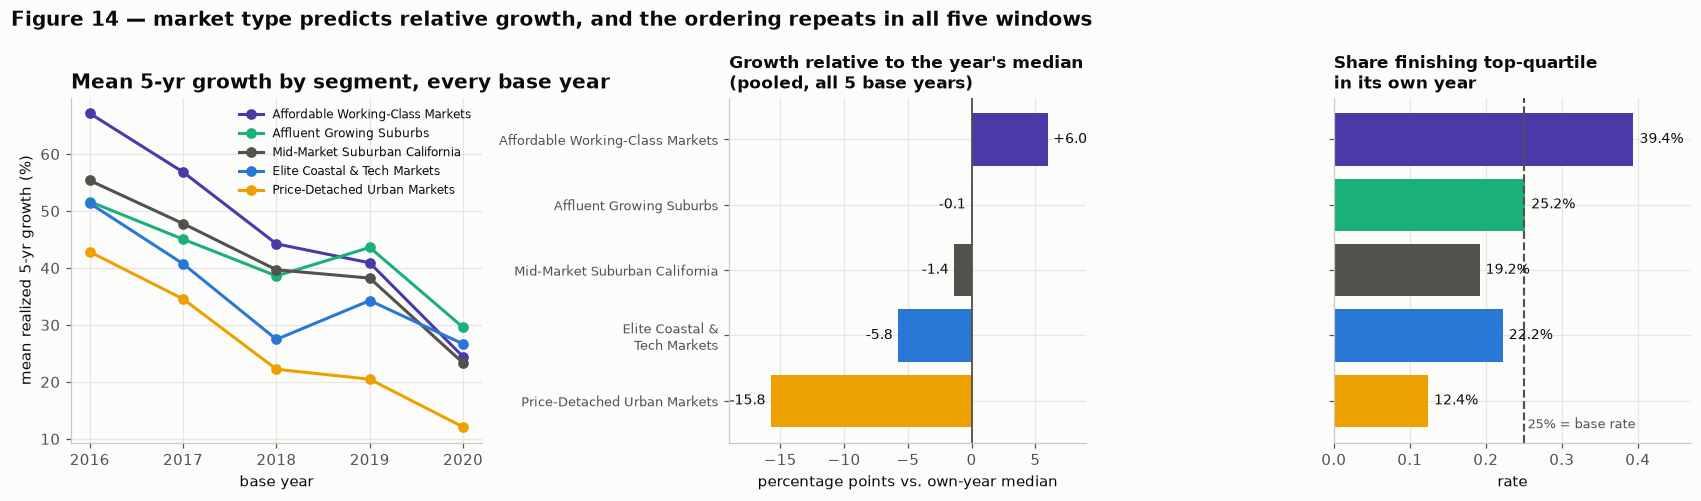

In [32]:
ordered = seg_summary.index.tolist()
cmap_seg = {NAMES[c]: CATEGORICAL[c] for c in sorted(NAMES)}

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6), gridspec_kw={"width_ratios": [1.15, 1, 1]})

ax = axes[0]
for seg in ordered:
    ax.plot(by_year_seg.columns, by_year_seg.loc[seg], marker="o", lw=2,
            color=cmap_seg[seg], label=seg)
ax.set_title("Mean 5-yr growth by segment, every base year")
ax.set_xlabel("base year"); ax.set_ylabel("mean realized 5-yr growth (%)")
ax.set_xticks(by_year_seg.columns)
ax.legend(fontsize=7.8, loc="upper right")

ax = axes[1]
vals = seg_summary["rel_growth_mean"]
ax.barh(range(len(vals)), vals.values[::-1], color=[cmap_seg[s] for s in vals.index[::-1]])
for i, v in enumerate(vals.values[::-1]):
    ax.text(v + (0.4 if v >= 0 else -0.4), i, f"{v:+.1f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9)
ax.axvline(0, color=GRAY, lw=1.2)
ax.set_yticks(range(len(vals)))
ax.set_yticklabels([s.replace(" & ", " &\n") for s in vals.index[::-1]], fontsize=8.2)
ax.set_xlim(-19, 9)
ax.set_title("Growth relative to the year's median\n(pooled, all 5 base years)", fontsize=11)
ax.set_xlabel("percentage points vs. own-year median")

ax = axes[2]
r_ = seg_summary["top_quartile_rate"]
ax.barh(range(len(r_)), r_.values[::-1], color=[cmap_seg[s] for s in r_.index[::-1]])
ax.axvline(0.25, color=GRAY, lw=1.4, ls="--")
ax.text(0.255, -0.42, "25% = base rate", color=GRAY, fontsize=8.5)
for i, v in enumerate(r_.values[::-1]):
    ax.text(v + 0.008, i, f"{v:.1%}", va="center", fontsize=9)
ax.set_yticks(range(len(r_))); ax.set_yticklabels([])
ax.set_xlim(0, 0.47)
ax.set_title("Share finishing top-quartile\nin its own year", fontsize=11)
ax.set_xlabel("rate")

fig.suptitle("Figure 14 — market type predicts relative growth, and the ordering repeats in all five windows",
             x=0.005, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "fig14_cluster_growth")
plt.show()

**Price-Detached Urban Markets** — roughly 129 ZIP codes, largely in central Los Angeles, where the
median home is ≈ \$1.06M against a median household income of ≈ \$67,750 — grew **15.8 points
slower** than their own year's median and finished top-quartile only 12.4% of the time. They rank
**last in all five five-year windows**. ANOVA across segments gives F = 27.5, p ≈ 4.6 × 10⁻²².

**Affordable Working-Class Markets** grew 6.0 points faster than their year's median and finished
top-quartile 39.4% of the time.

---
# 7. Association rules — which combinations of conditions co-occur with high growth?

Eight variables, each cut into terciles; each ZIP-year is one transaction. Two setup decisions had
to be corrected before the rules meant anything:

1. **`mortgage_rate` must be dropped.** It is constant within a base year, so its terciles *are*
   base years. Any rule containing it conditions on the year, not on a market characteristic.
2. **Growth terciles must be computed within base year.** Pooled globally, the growth terciles are
   also nearly a year indicator — 947 of 1,452 rows in 2016 land in the top tercile against 68 of
   1,528 in 2020.

The first run of this analysis (D3) used the pooled setup and produced four rules, one of which was
conditioning on the year. The corrected run below is the one reported.

In [33]:
SHORT = {"median_household_income": "Income", "price_to_income_ratio": "PriceToIncome",
         "unemployment_rate": "Unemployment", "bachelor_degree_pct": "Education",
         "population_growth_pct": "PopGrowth", "home_value_1yr_growth_pct": "Momentum",
         "mortgage_rate": "MortgageRate", TARGET: "FutureGrowth"}

print("mortgage_rate is constant within a base year -- five values across 7,487 rows:")
print(panel.groupby("base_year")["mortgage_rate"].first().round(3).to_string())
print("\nSo its terciles ARE base years:")
print(pd.crosstab(panel["base_year"],
                  pd.qcut(panel["mortgage_rate"], 3, labels=["Low", "Med", "High"])).to_string())
print("\nAnd POOLED growth terciles are almost base years too:")
print(pd.crosstab(panel["base_year"],
                  pd.qcut(panel[TARGET], 3, labels=["Low", "Med", "High"])).to_string())

mortgage_rate is constant within a base year -- five values across 7,487 rows:
base_year
2016   3.654
2017   3.990
2018   4.545
2019   3.936
2020   3.112

So its terciles ARE base years:
mortgage_rate   Low   Med  High
base_year                      
2016           1452     0     0
2017              0  1496     0
2018              0     0  1500
2019              0  1511     0
2020           1528     0     0

And POOLED growth terciles are almost base years too:
future_5yr_growth_pct   Low  Med  High
base_year                             
2016                     97  408   947
2017                    258  526   712
2018                    521  632   347
2019                    537  552   422
2020                   1083  377    68


In [34]:
def build_transactions(df, cols, growth_within_year=True):
    """Tercile-discretize each column and one-hot encode. Returns a boolean DataFrame."""
    parts = []
    for c in cols:
        if c == TARGET and growth_within_year:
            b = df.groupby("base_year")[c].transform(
                lambda s: pd.qcut(s, 3, labels=["Low", "Med", "High"]))
        else:
            b = pd.qcut(df[c], 3, labels=["Low", "Med", "High"])
        parts.append(b.rename(SHORT[c]))
    oh = pd.get_dummies(pd.concat(parts, axis=1))
    oh.columns = [c.replace("_", "=") for c in oh.columns]
    return oh.astype(bool)


RULE_COLS = [c for c in SHORT if c != "mortgage_rate"]
onehot = build_transactions(panel, RULE_COLS, growth_within_year=True)
print(f"transaction matrix: {onehot.shape[0]:,} transactions x {onehot.shape[1]} items"
      f"  (mortgage_rate dropped, growth binned within year)")
print("\ntercile boundaries -- what Low / Med / High actually mean:")
print(pd.DataFrame({SHORT[c]: panel[c].quantile([1/3, 2/3]).values for c in RULE_COLS},
                   index=["Low | Med", "Med | High"]).T.round(2).to_string())

freq = apriori(onehot, min_support=0.05, use_colnames=True, max_len=4)
rules = association_rules(freq, num_itemsets=len(onehot), metric="confidence", min_threshold=0.50)
kept = rules[rules["lift"] >= 1.20]
growth_rules = kept[kept["consequents"].apply(
    lambda s: all(i.startswith("FutureGrowth") for i in s))].copy()
growth_rules["antecedent"] = growth_rules["antecedents"].apply(lambda s: " & ".join(sorted(s)))
growth_rules["consequent"] = growth_rules["consequents"].apply(lambda s: " & ".join(sorted(s)))
growth_rules = growth_rules.sort_values("lift", ascending=False)

print(f"\nfrequent itemsets (support >= 0.05): {len(freq):,}")
print(f"rules with a growth consequent, confidence >= 0.50 and lift >= 1.20: {len(growth_rules)}")
print(f"  by consequent: {growth_rules['consequent'].value_counts().to_dict()}")
print(f"  lift {growth_rules['lift'].min():.3f} to {growth_rules['lift'].max():.3f}"
      f" | support {growth_rules['support'].min():.3f} to {growth_rules['support'].max():.3f}"
      f" ({growth_rules['support'].min()*len(panel):,.0f} to {growth_rules['support'].max()*len(panel):,.0f} ZIP-years)")
print()
print(growth_rules[["antecedent", "consequent", "support", "confidence", "lift"]].to_string(index=False))

transaction matrix: 7,487 transactions x 21 items  (mortgage_rate dropped, growth binned within year)

tercile boundaries -- what Low / Med / High actually mean:
               Low | Med  Med | High
Income        55,947.330  81,916.000
PriceToIncome      6.050       8.840
Unemployment       5.200       8.090
Education         19.990      39.180
PopGrowth          0.420       5.550
Momentum           5.150       9.260
FutureGrowth      33.780      49.580

frequent itemsets (support >= 0.05): 377
rules with a growth consequent, confidence >= 0.50 and lift >= 1.20: 26
  by consequent: {'FutureGrowth=High': 17, 'FutureGrowth=Low': 9}
  lift 1.524 to 1.874 | support 0.051 to 0.118 (380 to 880 ZIP-years)

                                            antecedent        consequent  support  confidence  lift
    Income=Low & PriceToIncome=Low & Unemployment=High FutureGrowth=High    0.066       0.625 1.874
        Education=Low & Income=Low & PriceToIncome=Low FutureGrowth=High    0.073       0.6

In [35]:
# Every single-condition rule, so the tails can be compared on equal footing.
single = association_rules(freq, num_itemsets=len(onehot), metric="confidence", min_threshold=0.0)
single = single[(single["antecedents"].apply(len) == 1) &
                (single["consequents"].apply(lambda s: all(i.startswith("FutureGrowth") for i in s)))].copy()
single["condition"] = single["antecedents"].apply(lambda s: list(s)[0])
single["growth bin"] = single["consequents"].apply(lambda s: list(s)[0])
lift_tbl = single.pivot_table(index="condition", columns="growth bin", values="lift")
print("Lift of each single condition against each growth tercile  (1.00 = no information)")
print(lift_tbl.round(3).to_string())

for con in ["FutureGrowth=High", "FutureGrowth=Low"]:
    top = lift_tbl[con].sort_values(ascending=False).head(4)
    print(f"\n-> {con}: " + ",  ".join(f"{k} ({v:.2f})" for k, v in top.items()))

for c, b in [("PriceToIncome=High", "FutureGrowth=Low"), ("PriceToIncome=Low", "FutureGrowth=High")]:
    row = single[(single.condition == c) & (single["growth bin"] == b)].iloc[0]
    print(f"\n{{{c}}} -> {{{b}}}   support {row.support:.3f}"
          f" ({row.support * len(panel):,.0f} ZIP-years)  confidence {row.confidence:.3f}"
          f"  lift {row.lift:.3f}")

n_lo = growth_rules[growth_rules.consequent == "FutureGrowth=Low"]["antecedent"].str.contains("PriceToIncome").sum()
n_hi = growth_rules[growth_rules.consequent == "FutureGrowth=High"]["antecedent"].str.contains("PriceToIncome").sum()
print(f"\nPriceToIncome appears in {n_lo} of "
      f"{(growth_rules.consequent == 'FutureGrowth=Low').sum()} low-growth rules and {n_hi} of "
      f"{(growth_rules.consequent == 'FutureGrowth=High').sum()} high-growth rules.")

Lift of each single condition against each growth tercile  (1.00 = no information)
growth bin          FutureGrowth=High  FutureGrowth=Low  FutureGrowth=Med
condition                                                                
Education=High                  0.850             1.285             0.865
Education=Low                   1.428             0.586             0.986
Education=Med                   0.723             1.128             1.149
Income=High                     0.874             1.115             1.011
Income=Low                      1.262             0.852             0.886
Income=Med                      0.864             1.034             1.102
Momentum=High                   1.120             0.832             1.048
Momentum=Low                    0.961             1.166             0.872
Momentum=Med                    0.919             1.001             1.080
PopGrowth=High                  0.948             1.102             0.950
PopGrowth=Low                

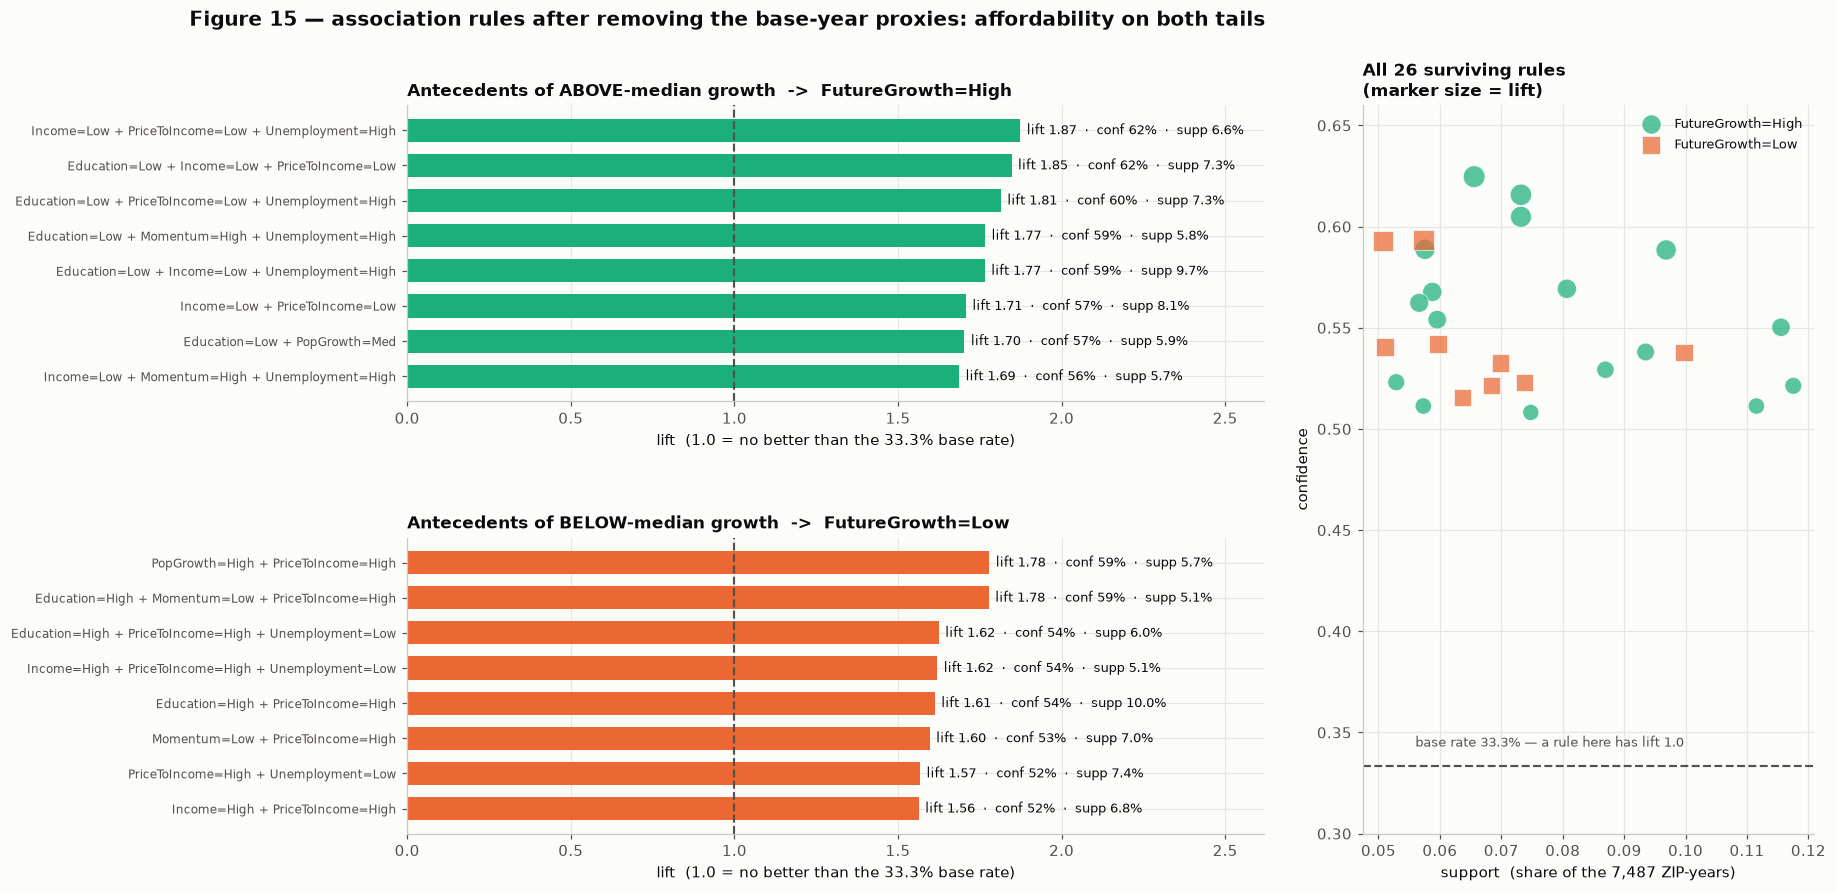

In [36]:
top_hi = growth_rules[growth_rules.consequent == "FutureGrowth=High"].head(8)
top_lo = growth_rules[growth_rules.consequent == "FutureGrowth=Low"].head(8)

fig = plt.figure(figsize=(16.5, 8.6))
gsr = fig.add_gridspec(2, 2, width_ratios=[1.9, 1], hspace=0.46, wspace=0.15)

def rule_bars(ax, df, color, title):
    lab = [a.replace(" & ", " + ") for a in df["antecedent"]][::-1]
    ax.barh(range(len(df)), df["lift"].values[::-1], color=color, height=0.66)
    for i, (l, c, s) in enumerate(zip(df["lift"].values[::-1], df["confidence"].values[::-1],
                                      df["support"].values[::-1])):
        ax.text(l + 0.02, i, f"lift {l:.2f}  ·  conf {c:.0%}  ·  supp {s:.1%}",
                va="center", fontsize=8.4)
    ax.set_yticks(range(len(df))); ax.set_yticklabels(lab, fontsize=8.0)
    ax.axvline(1.0, color=GRAY, lw=1.4, ls="--")
    ax.set_xlim(0, 2.62)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("lift  (1.0 = no better than the 33.3% base rate)")

rule_bars(fig.add_subplot(gsr[0, 0]), top_hi, GREEN,
          "Antecedents of ABOVE-median growth  ->  FutureGrowth=High")
rule_bars(fig.add_subplot(gsr[1, 0]), top_lo, ACCENT,
          "Antecedents of BELOW-median growth  ->  FutureGrowth=Low")

ax = fig.add_subplot(gsr[:, 1])
for con, color, mark in [("FutureGrowth=High", GREEN, "o"), ("FutureGrowth=Low", ACCENT, "s")]:
    d = growth_rules[growth_rules.consequent == con]
    ax.scatter(d["support"], d["confidence"], s=28 + (d["lift"] - 1.2) * 260, marker=mark,
               color=color, alpha=0.72, edgecolor="white", lw=0.6, label=con)
ax.axhline(1 / 3, color=GRAY, lw=1.4, ls="--")
ax.text(0.056, 0.343, "base rate 33.3% — a rule here has lift 1.0", color=GRAY, fontsize=8.4)
ax.set_xlabel("support  (share of the 7,487 ZIP-years)")
ax.set_ylabel("confidence")
ax.set_ylim(0.30, 0.66)
ax.set_title(f"All {len(growth_rules)} surviving rules\n(marker size = lift)", fontsize=11)
ax.legend(fontsize=8.5, loc="upper right")

fig.suptitle("Figure 15 — association rules after removing the base-year proxies: affordability on both tails",
             x=0.005, ha="left", fontweight="bold", fontsize=13)
save(fig, "fig15_association_rules")
plt.show()

### The asymmetry, in plain language

`PriceToIncome` appears on **both** tails, with opposite direction — but the two sides are **not**
mirror images:

- **A high price-to-income ratio alone** is the strongest single condition in the entire item set:
  lift 1.41 across 15.7% of the panel (1,177 ZIP-years). *Unaffordability predicts underperformance
  without needing to be combined with anything.*
- **A low price-to-income ratio alone** reaches lift 1.23, and must be combined with low income and
  high unemployment before lift reaches 1.87. *Affordability alone is not sufficient to predict
  outperformance.*

No rule predicts the **middle** tercile. Combinations of extreme conditions identify the tails of
the distribution and say nothing about ordinary markets.

---
# 8. Synthesis — primary, secondary and weak predictors

This is the section the whole project builds toward. The classification below is produced by an
**explicitly stated rule applied to two independent methods**, not by inspection:

| Evidence | What it measures | Why it is used |
|---|---|---|
| **Ridge standardized coefficient rank** (relative target) | direction and magnitude in a linear, regularized model | penalty shares weight across correlated predictors instead of arbitrarily crowning one |
| **Grouped permutation importance** (block level, val + test, Ridge + RF) | out-of-sample loss when a whole correlated block is destroyed | per-feature permutation is unusable here — a feature's twin covers for it (§4.4) |
| **Sign consistency across all five base years** | whether the association survives a regime change | a predictor whose direction flips is not a stable predictor, whatever its coefficient |

**The rule, stated before looking at the answer:**

- **Primary** — sign-consistent in all five base years **and** Ridge |coef| rank in the top half
  **and** in a block whose grouped importance is positive in *all four* val/test × Ridge/RF cells.
- **Secondary** — otherwise, Ridge rank ≤ 8 **or** per-feature permutation rank ≤ 4.
- **Weak** — everything else.

`mortgage_rate` and `estimated_monthly_mortgage` are excluded from the ranking entirely and reported
separately: they are base-year indices, not ZIP-level predictors (§4.5).

In [37]:
evidence = pd.DataFrame({
    "Ridge coef (std)": coefs,
    "Ridge rank": coefs.abs().rank(ascending=False).astype(int),
    "Perm imp (RF)": perm_rf,
    "Perm rank": perm_rf.rank(ascending=False).astype(int),
    "block": pd.Series({c: b for b, cols in BLOCKS.items() for c in cols}),
})
evidence["block grouped imp"] = evidence["block"].map(grouped["mean"])
evidence["block always +"] = evidence["block"].map(
    (grouped.drop(columns="mean") > 0).all(axis=1))
evidence["sign consistent"] = stability["sign consistent"].eq("yes")

n_feat = len(evidence)
primary = (evidence["sign consistent"] & evidence["block always +"]
           & (evidence["Ridge rank"] <= n_feat // 2))
secondary = ~primary & ((evidence["Ridge rank"] <= 8) | (evidence["Perm rank"] <= 4))
evidence["category"] = np.select([primary, secondary], ["PRIMARY", "SECONDARY"], "WEAK")

evidence = evidence.sort_values(
    ["category", "Ridge rank"],
    key=lambda s: s.map({"PRIMARY": 0, "SECONDARY": 1, "WEAK": 2}) if s.name == "category" else s)
print(evidence[["category", "block", "Ridge coef (std)", "Ridge rank", "Perm rank",
                "block grouped imp", "sign consistent"]].round(3).to_string())
print("\ncounts:", evidence["category"].value_counts().to_dict())

                            category            block  Ridge coef (std)  Ridge rank  Perm rank  block grouped imp  sign consistent
mortgage_to_income_ratio     PRIMARY    Affordability            -2.573           1         11              1.462             True
price_to_income_ratio        PRIMARY    Affordability            -2.241           2         10              1.462             True
price_to_rent_ratio          PRIMARY    Affordability            -2.157           3          7              1.462             True
population                   PRIMARY      Urban scale             1.660           6          1              1.541             True
home_value_1yr_growth_pct  SECONDARY         Momentum             1.730           4          4              0.092            False
bachelor_degree_pct        SECONDARY  Affluence level            -1.723           5          5              0.211            False
unemployment_rate          SECONDARY     Labor market             1.634           7

In [38]:
# The same conclusion, reached by three methods that share no assumptions.
converge = pd.DataFrame([
    {"Method": "Ridge regression (relative target)", "Family": "linear / penalized",
     "What it says about affordability":
         f"3 of the 4 largest |coefficients| are affordability ratios "
         f"(p2i {coefs['price_to_income_ratio']:+.2f}, p2r {coefs['price_to_rent_ratio']:+.2f}, "
         f"m2i {coefs['mortgage_to_income_ratio']:+.2f}), all negative"},
    {"Method": "Logistic regression (within-year label)", "Family": "likelihood",
     "What it says about affordability":
         f"largest stable negative coefficient is price_to_rent_ratio, "
         f"odds ratio {np.exp(lr_coefs['price_to_rent_ratio']):.2f} per +1 SD"},
    {"Method": "K-Means (outcome never seen)", "Family": "distance / unsupervised",
     "What it says about affordability":
         f"the extreme price-to-income segment finished LAST in all 5 windows, "
         f"{seg_summary.loc['Price-Detached Urban Markets', 'rel_growth_mean']:+.1f} pts vs. year median"},
    {"Method": "Apriori (co-occurrence counts)", "Family": "frequency",
     "What it says about affordability":
         f"PriceToIncome appears in {n_lo}/{(growth_rules.consequent=='FutureGrowth=Low').sum()} low-growth "
         f"and {n_hi}/{(growth_rules.consequent=='FutureGrowth=High').sum()} high-growth rules, opposite signs"},
])
print(converge.to_string(index=False))

                                 Method                  Family                                                                           What it says about affordability
     Ridge regression (relative target)      linear / penalized 3 of the 4 largest |coefficients| are affordability ratios (p2i -2.24, p2r -2.16, m2i -2.57), all negative
Logistic regression (within-year label)              likelihood                      largest stable negative coefficient is price_to_rent_ratio, odds ratio 0.21 per +1 SD
           K-Means (outcome never seen) distance / unsupervised              the extreme price-to-income segment finished LAST in all 5 windows, -15.8 pts vs. year median
         Apriori (co-occurrence counts)               frequency                         PriceToIncome appears in 9/9 low-growth and 7/17 high-growth rules, opposite signs


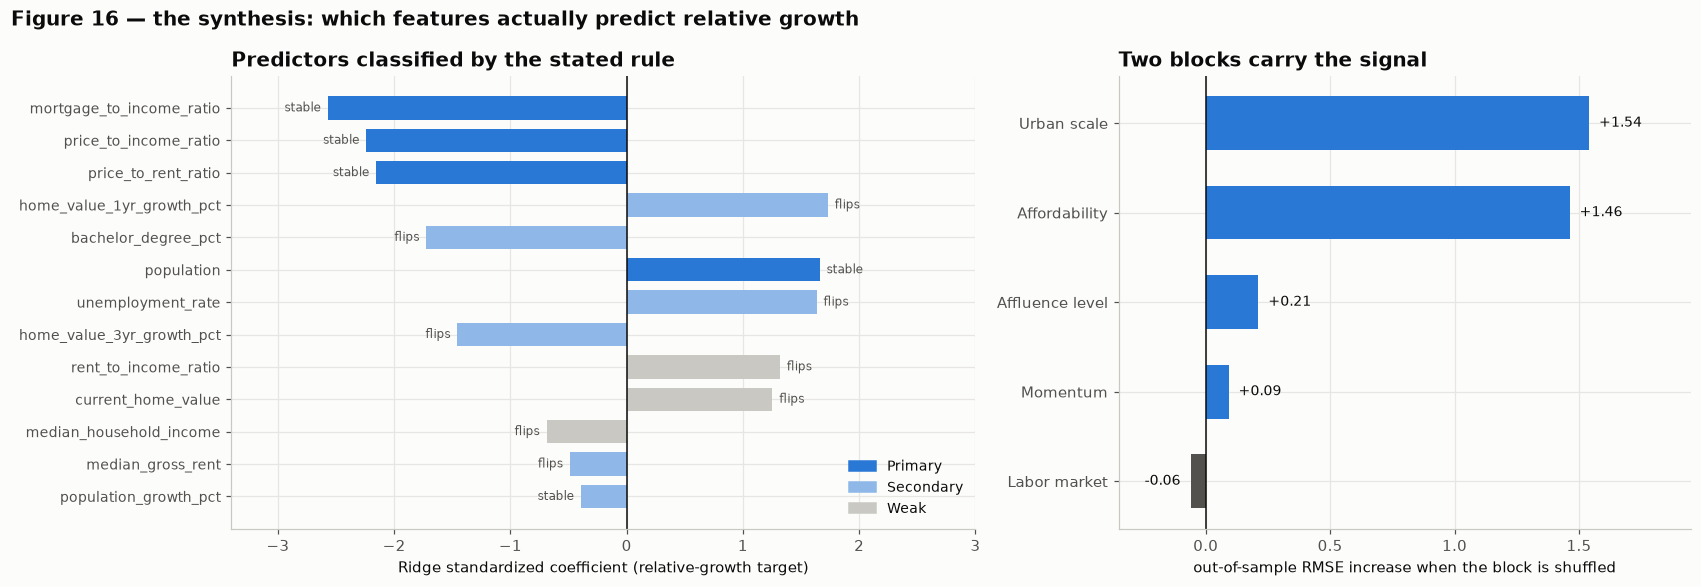

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.4), gridspec_kw={"width_ratios": [1.3, 1]})

ax = axes[0]
cat_color = {"PRIMARY": BLUE, "SECONDARY": "#8fb8e8", "WEAK": "#c9c8c3"}
ev = evidence.sort_values("Ridge coef (std)", key=abs)
ax.barh(range(len(ev)), ev["Ridge coef (std)"].values,
        color=[cat_color[c] for c in ev["category"]], height=0.72)
for i, (v, cat, sc) in enumerate(zip(ev["Ridge coef (std)"], ev["category"], ev["sign consistent"])):
    ax.text(v + (0.06 if v >= 0 else -0.06), i, "stable" if sc else "flips", va="center",
            ha="left" if v >= 0 else "right", fontsize=7.6, color=GRAY)
ax.set_yticks(range(len(ev))); ax.set_yticklabels(ev.index, fontsize=9)
ax.axvline(0, color="#0b0b0b", lw=1)
ax.set_xlim(-3.4, 3.0)
ax.set_xlabel("Ridge standardized coefficient (relative-growth target)")
ax.set_title("Predictors classified by the stated rule")
handles = [plt.Rectangle((0, 0), 1, 1, color=cat_color[c]) for c in ["PRIMARY", "SECONDARY", "WEAK"]]
ax.legend(handles, ["Primary", "Secondary", "Weak"], fontsize=9, loc="lower right")

ax = axes[1]
g = grouped["mean"].sort_values()
ax.barh(range(len(g)), g.values, color=[GRAY if v < 0 else BLUE for v in g.values], height=0.6)
for i, v in enumerate(g.values):
    ax.text(v + (0.04 if v >= 0 else -0.04), i, f"{v:+.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9)
ax.set_yticks(range(len(g))); ax.set_yticklabels(g.index, fontsize=10)
ax.axvline(0, color="#0b0b0b", lw=1)
ax.set_xlim(-0.35, 1.95)
ax.set_xlabel("out-of-sample RMSE increase when the block is shuffled")
ax.set_title("Two blocks carry the signal")

fig.suptitle("Figure 16 — the synthesis: which features actually predict relative growth",
             x=0.005, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "fig16_synthesis")
plt.show()

### Reading the table

**Primary — affordability and urban scale.** `mortgage_to_income_ratio`, `price_to_income_ratio`,
`price_to_rent_ratio` and `population` are the only features that are both large in the penalized
linear model and stable in direction across all five regimes, and they sit in the only two blocks
that survive grouped permutation on both held-out years. All three affordability terms are
**negative**: less affordable → lower subsequent relative growth. `population` is **positive**:
larger, more urban ZIP codes outgrew small ones over these windows.

**Secondary — affluence and momentum.** Education, home value level, income, rent and the momentum
terms all carry weight in at least one model, but their sign **flips across base years**. Their
correlation with relative growth is strongly negative in 2016–2018 and turns positive by 2020.
That is not a stable relationship; it is a phase of the cycle. They matter for prediction and
should not be described as drivers.

**Weak — the rest.** `population_growth_pct` is sign-consistent but tiny. `unemployment_rate` is
interesting in the association rules yet unstable in the regression. `rent_to_income_ratio` adds
little beyond the other affordability terms.

**Excluded — `mortgage_rate`.** Zero within-year variance and therefore zero ability to explain why
one ZIP code outgrew another. It explains why one *year* differed from another, and there are only
five years here.

### Four methods, one answer

The strongest claim this project can make is not any single number. It is that a **penalized linear
model**, a **likelihood-based classifier**, a **distance-based unsupervised method that never saw
the outcome**, and a **frequency-based rule miner** — four families with essentially no shared
assumptions — all place affordability at the centre. Agreement across that many unrelated methods
is stronger evidence than any one of them alone.

---
# 9. Forecast to 2029

The forecast frame is 1,543 California ZIP codes at base year **2024**, built by the same pipeline
as the panel. Final models are refit on **all five base years** — once evaluation is finished there
is no held-out year left to protect, and the forecast should use every observation available.

## 9.1 The extrapolation problem, stated before the numbers

Training mortgage rates span **3.11–4.55%**. The 2024 input is **6.72%** — outside the training
range entirely, for 100% of rows. **Random Forests cannot extrapolate**: they clamp to the edge of
what they have seen. So the forecast is produced **both with and without** the rate features, and
the divergence is reported rather than smoothed over.

In [40]:
forecast = engineer(pd.read_csv(PROC / "ca_zip_forecast_frame_2024.csv", dtype={"zip_code": str}))
print(f"forecast frame: {len(forecast):,} California ZIP codes, base year 2024\n")

cov = [{"feature": c, "train min": panel[c].min(), "train max": panel[c].max(),
        "2024 median": forecast[c].median(),
        "% of 2024 rows above train max": (forecast[c] > panel[c].max()).mean() * 100}
       for c in ["mortgage_rate", "current_home_value", "mortgage_to_income_ratio",
                 "price_to_income_ratio", "price_to_rent_ratio"]]
print(pd.DataFrame(cov).set_index("feature").round(3).to_string())

forecast frame: 1,543 California ZIP codes, base year 2024

                          train min     train max  2024 median  % of 2024 rows above train max
feature                                                                                       
mortgage_rate                 3.112         4.545        6.721                         100.000
current_home_value       45,530.059 6,483,301.321  723,096.226                           0.065
mortgage_to_income_ratio      0.052         3.749        0.467                           0.065
price_to_income_ratio         1.185        81.893        7.526                           0.065
price_to_rent_ratio           4.056       296.643       31.177                           0.000


In [41]:
def fit_final(feats):
    rf = RandomForestRegressor(n_estimators=400, min_samples_leaf=5, max_features=0.5,
                               random_state=RANDOM_STATE, n_jobs=-1).fit(panel[feats], panel[TARGET])
    rg = Pipeline([("scaler", StandardScaler()),
                   ("model", Ridge(alpha=1000.0))]).fit(panel[feats], panel[TARGET])
    return rf, rg

rf_rate, rg_rate = fit_final(FEATURES)
rf_norate, rg_norate = fit_final(NO_RATE)

fc_preds = {"Random Forest, with rate": rf_rate.predict(forecast[FEATURES]),
            "Random Forest, no rate":   rf_norate.predict(forecast[NO_RATE]),
            "Ridge, with rate":         rg_rate.predict(forecast[FEATURES]),
            "Ridge, no rate":           rg_norate.predict(forecast[NO_RATE])}
print(pd.DataFrame({k: pd.Series(v).describe(percentiles=[.1, .5, .9])
                    for k, v in fc_preds.items()}).T[["mean", "10%", "50%", "90%"]].round(2))

                           mean    10%    50%    90%
Random Forest, with rate 38.970 26.870 40.310 49.800
Random Forest, no rate   38.570 23.680 39.520 51.340
Ridge, with rate         57.520 49.880 57.870 64.760
Ridge, no rate           37.450 29.480 37.890 45.060


Ridge *with* the rate predicts a mean of 57.5% — it extrapolates the historical rate–growth slope
straight through a 6.7% world and produces a number nobody should believe. **Ridge without the rate
lands at 37.5%, and Random Forest at 38.6–39.0% either way**, because the forest simply clamps.

The reported forecast is **Random Forest without the rate features** — the configuration that had
the best out-of-time test RMSE in §4 and the one whose failure mode is understood.

## 9.2 Uncertainty from the model's own out-of-time error

The honest uncertainty here is not the training-fold residual spread. It is **how wrong this model
was the last time it was asked about a year it had never seen** — the 2020 test set. Those residuals
are centred at **−23.1 points** with an 80% range of −43.6 to −5.6.

Both quantiles are **negative**, so the interval sits *entirely below* the point estimate. That
asymmetry is the result, not a plotting artifact: the last time this model faced an unseen year, it
over-predicted growth every time.

In [42]:
_, _, preds_nr_test = evaluate({"Random Forest": RandomForestRegressor(
    n_estimators=400, min_samples_leaf=5, max_features=0.5,
    random_state=RANDOM_STATE, n_jobs=-1)},
    train[NO_RATE], y_train, groups, val[NO_RATE], y_val, test[NO_RATE], y_test)

oot_resid = y_test.to_numpy() - preds_nr_test["Random Forest"]["test"]
q10, q50, q90 = np.percentile(oot_resid, [10, 50, 90])
print("Out-of-time residual distribution (base year 2020, RF without rate features)")
print(f"  mean {oot_resid.mean():+.2f}   sd {oot_resid.std():.2f}")
print(f"  10th {q10:+.2f}   median {q50:+.2f}   90th {q90:+.2f}  (percentage points)")

forecast["predicted_5yr_growth_pct"] = fc_preds["Random Forest, no rate"]
forecast["predicted_growth_lo"] = forecast["predicted_5yr_growth_pct"] + q10
forecast["predicted_growth_hi"] = forecast["predicted_5yr_growth_pct"] + q90
for col, g in [("predicted_home_value_2029", "predicted_5yr_growth_pct"),
               ("predicted_value_2029_lo", "predicted_growth_lo"),
               ("predicted_value_2029_hi", "predicted_growth_hi")]:
    forecast[col] = forecast["current_home_value"] * (1 + forecast[g] / 100)

forecast["affordability_group"] = pd.qcut(
    forecast["mortgage_to_income_ratio"], 4,
    labels=["Q1 most affordable", "Q2", "Q3", "Q4 least affordable"])

print(f"\nPoint forecast   median 2024 value ${forecast['current_home_value'].median():,.0f}"
      f"  ->  2029 ${forecast['predicted_home_value_2029'].median():,.0f}"
      f"   ({forecast['predicted_5yr_growth_pct'].median():.1f}%)")
print(f"80% interval     ${forecast['predicted_value_2029_lo'].median():,.0f}"
      f"  to  ${forecast['predicted_value_2029_hi'].median():,.0f}"
      f"   ({forecast['predicted_growth_lo'].median():.1f}% to {forecast['predicted_growth_hi'].median():.1f}%)")

print("\nBy affordability quartile:")
print(forecast.groupby("affordability_group", observed=True).agg(
    zips=("zip_code", "size"),
    median_mortgage_to_income=("mortgage_to_income_ratio", "median"),
    median_value_2024=("current_home_value", "median"),
    median_predicted_growth=("predicted_5yr_growth_pct", "median"),
    median_value_2029=("predicted_home_value_2029", "median")).round(2).to_string())

Out-of-time residual distribution (base year 2020, RF without rate features)
  mean -23.10   sd 16.75
  10th -43.63   median -21.45   90th -5.55  (percentage points)

Point forecast   median 2024 value $723,096  ->  2029 $1,017,114   (39.5%)
80% interval     $699,947  to  $976,099   (-4.1% to 34.0%)

By affordability quartile:
                     zips  median_mortgage_to_income  median_value_2024  median_predicted_growth  median_value_2029
affordability_group                                                                                                
Q1 most affordable    386                      0.300        380,752.900                   40.450        525,666.670
Q2                    386                      0.400        575,286.640                   45.220        797,512.000
Q3                    385                      0.540        902,044.410                   40.400      1,283,241.790
Q4 least affordable   386                      0.750      1,289,035.220                   3

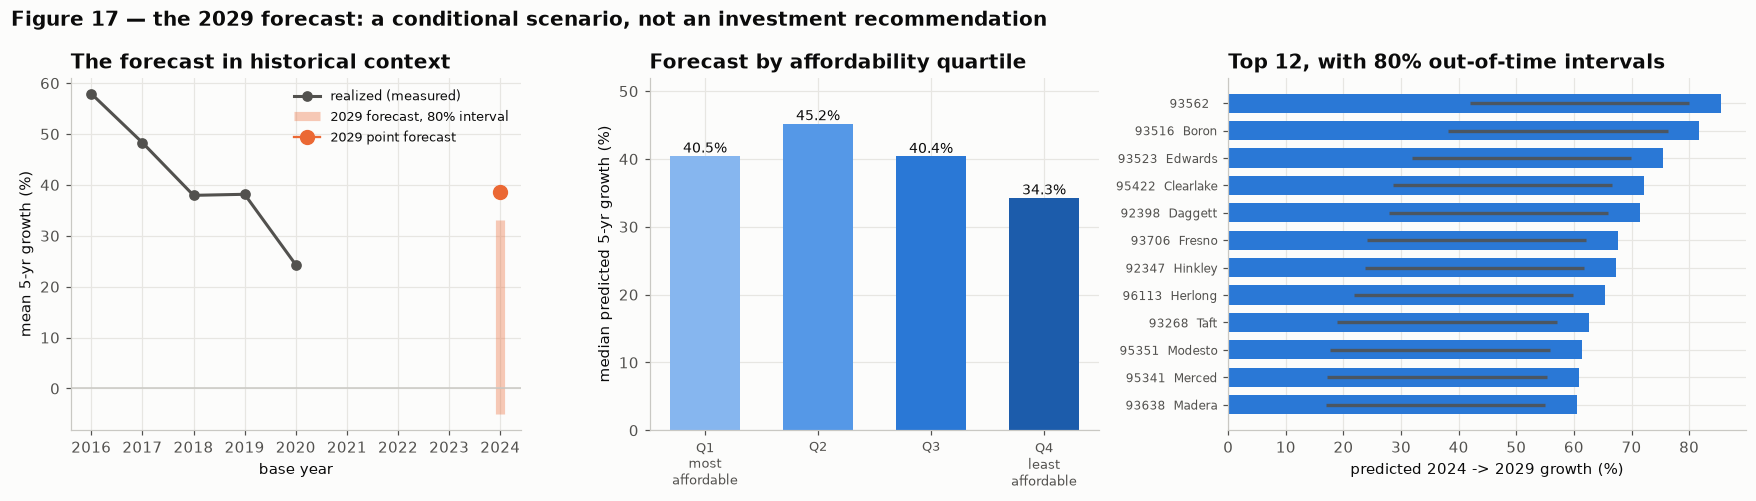

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.15]})

ax = axes[0]
hist_mean = panel.groupby("base_year")[TARGET].mean()
ax.plot(hist_mean.index, hist_mean.values, marker="o", color=GRAY, lw=2, label="realized (measured)")
pt = forecast["predicted_5yr_growth_pct"].mean()
ax.vlines(2024, pt + q10, pt + q90, color=ACCENT, lw=6, alpha=0.35,
          label="2029 forecast, 80% interval")
ax.plot([2024], [pt], marker="o", color=ACCENT, markersize=9, label="2029 point forecast")
ax.axhline(0, color="#c9c8c3", lw=1)
ax.set_xlabel("base year"); ax.set_ylabel("mean 5-yr growth (%)")
ax.set_title("The forecast in historical context")
ax.legend(fontsize=8.5)

ax = axes[1]
grp = forecast.groupby("affordability_group", observed=True)["predicted_5yr_growth_pct"].median()
ax.bar(range(4), grp.values, color=YEAR_COLORS[:4], width=0.62)
for i, v in enumerate(grp.values):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center", fontsize=9)
ax.set_xticks(range(4))
ax.set_xticklabels([s.replace(" ", "\n") for s in grp.index], fontsize=8.5)
ax.set_ylabel("median predicted 5-yr growth (%)")
ax.set_ylim(0, 52)
ax.set_title("Forecast by affordability quartile")

ax = axes[2]
top = forecast.nlargest(12, "predicted_5yr_growth_pct").iloc[::-1]
lbl = [f"{z}  {c if isinstance(c, str) else ''}"[:24] for z, c in zip(top["zip_code"], top["city"])]
ax.barh(range(len(top)), top["predicted_5yr_growth_pct"], color=BLUE, height=0.7)
ax.hlines(range(len(top)), top["predicted_growth_lo"], top["predicted_growth_hi"],
          color=GRAY, lw=2.2, alpha=0.85)
ax.axvline(0, color="#0b0b0b", lw=1)
ax.set_yticks(range(len(top))); ax.set_yticklabels(lbl, fontsize=8)
ax.set_xlabel("predicted 2024 -> 2029 growth (%)")
ax.set_title("Top 12, with 80% out-of-time intervals")

fig.suptitle("Figure 17 — the 2029 forecast: a conditional scenario, not an investment recommendation",
             x=0.005, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "fig17_forecast")
plt.show()

In [44]:
cols = ["zip_code", "city", "county", "current_home_value", "predicted_5yr_growth_pct",
        "predicted_home_value_2029", "predicted_growth_lo", "predicted_growth_hi"]
print("TOP 10 predicted five-year growth (2024 -> 2029)")
print(forecast.nlargest(10, "predicted_5yr_growth_pct")[cols].round(1).to_string(index=False))
print("\nBOTTOM 10 predicted five-year growth (2024 -> 2029)")
print(forecast.nsmallest(10, "predicted_5yr_growth_pct")[cols].round(1).to_string(index=False))

OUT_FC = PROC / "forecast_2029_by_zip.csv"
forecast[["zip_code", "city", "county", "base_year", "current_home_value",
          "mortgage_to_income_ratio", "price_to_income_ratio", "affordability_group",
          "predicted_5yr_growth_pct", "predicted_growth_lo", "predicted_growth_hi",
          "predicted_home_value_2029", "predicted_value_2029_lo",
          "predicted_value_2029_hi"]].to_csv(OUT_FC, index=False)
print(f"\nwrote {OUT_FC.relative_to(ROOT)}  ({len(forecast):,} rows)")

TOP 10 predicted five-year growth (2024 -> 2029)
zip_code      city                county  current_home_value  predicted_5yr_growth_pct  predicted_home_value_2029  predicted_growth_lo  predicted_growth_hi
   93562       NaN           Kern County          71,026.200                    85.500                131,782.800               41.900               80.000
   93516     Boron           Kern County         179,083.900                    81.800                325,568.800               38.200               76.200
   93523   Edwards           Kern County         212,235.400                    75.500                372,400.300               31.800               69.900
   95422 Clearlake           Lake County         221,614.300                    72.200                381,607.000               28.600               66.600
   92398   Daggett San Bernardino County         186,777.700                    71.500                320,239.900               27.800               65.900
   93706    Fre

### How to read the forecast — and how not to

The high end of the list is dominated by **Kern County, Lake County, the San Bernardino desert and
the Central Valley**; the low end by **high-priced central Los Angeles ZIP codes**. That ordering is
the affordability finding restated on 2024 data.

Four caveats, none optional:

1. **The level should be discounted.** Every training window contained the pandemic boom. The last
   time this model met an unseen year it over-predicted by 23 points on average.
2. **The 80% interval lies entirely below the point estimate** for exactly that reason.
3. **The ranking is the usable output**, not the dollar values. §4 showed the ranking survives
   out-of-time and the level does not.
4. **A prediction of "high growth" is a prediction about a price index, not a recommendation.** The
   fastest-predicted ZIP codes are also the lowest-priced and least liquid markets in the state.

---
# 10. Conclusions, recommendations, ethics and limitations

## 10.1 Answering the two research questions

**Q1 — Which factors are associated with five-year home price growth?**
Affordability (price-to-income, price-to-rent, mortgage-payment-to-income) and urban scale
(population) are the primary predictors: large in a penalized linear model, stable in sign across
all five base years, and the only two blocks that survive grouped permutation out of sample.
Affluence and momentum features are secondary — they carry weight but flip sign across the cycle.
The mortgage rate is a macro control, not a ZIP-level predictor.

**Q2 — What will homes be worth in 2029?**
Median California ZIP code: \$723k in 2024 → **≈ \$1.02M in 2029 (+39.5%)**, with an 80% interval
of **\$700k to \$976k (−4.1% to +34.0%)**. The interval sits below the point estimate because the
model's own out-of-time error was one-sided. **The ranking of ZIP codes is far more trustworthy than
the level**, and the level should be read as *"what would happen if the next five years resembled
the last five"* — which they very likely will not.

## 10.2 Practical recommendations

Each is hedged, because each deserves to be.

**For homebuyers.** ZIP codes where homes cost roughly **8.8× local median income or more** have
historically been below-median appreciation markets. That is a statement about one price index over
one five-year window — it says nothing about schools, commute, safety, or any of the reasons people
actually choose where to live, and *a home is not primarily an investment.* Treat it as one input
among many, not a filter.

**For investors.** The conjunction of *low price-to-income + low income + high unemployment* is a
screening rule with 62.5% confidence over 491 ZIP-years — and **more than a third of the ZIP codes
passing that screen still failed to beat the median.** The model ranks; it does not select. Use it
to generate a shortlist for due diligence, never as a decision rule. Note also that the
highest-predicted ZIP codes are the smallest and least liquid markets in California, where entry
and exit costs are highest and a single local shock can dominate.

**For city planners.** The pattern most relevant to policy is that jurisdictions **growing in
population while already unaffordable** were the most likely to underperform — a statement about
the widening gap between housing costs and local earnings, not about returns. The Price-Detached
segment (≈ \$1.06M homes against ≈ \$67,750 incomes, largely central Los Angeles) is where that gap
is widest and where it persisted across all five windows.

**For everyone.** **This model is not an investment guarantee and must not be presented as one.**
It explains, at best, 12% of the variance in relative five-year growth on a year it had not seen.

## 10.3 Ethical considerations

### ZIP code is a proxy for race and class — this is the central ethical issue

ZIP codes in the United States are **not** race-neutral geography. Decades of segregation, restrictive
covenants, and discriminatory lending produced ZIP codes that differ sharply by race and class, and
those differences persist. A model keyed on **ZIP-level income, education, and home value can
reproduce racial patterns with no race variable anywhere in it.** `bachelor_degree_pct` and
`median_household_income` are not neutral measurements of a neighborhood — they are partly the
accumulated residue of who was permitted to buy where, and when.

Removing race from the feature list does not remove race from the model. It only removes the ability
to *measure* what the model is doing.

### Historical housing data carries the imprint of redlining

The target itself — realized home-price appreciation — is an outcome shaped by the same history.
Neighborhoods graded "hazardous" by the Home Owners' Loan Corporation in the 1930s were starved of
mortgage credit for decades, and the resulting price trajectories are in this dataset. **A model
trained on those outcomes learns the pattern that discrimination produced** and will project it
forward as though it were a law of markets.

### This model must never be used for lending, insurance, or tenant screening

This is the sharpest point in the report and it is stated without hedging. Predicting that a ZIP
code will underperform, and then **acting** on that prediction by withholding credit, raising
premiums, or screening tenants, is **precisely the mechanism of redlining, restated in the language
of machine learning.** The fact that the model is statistical, tested, and well-intentioned changes
nothing about its effect. Legitimate uses are descriptive and aggregate — research, planning,
market analysis. Any use that determines an *individual's* access to housing or credit is
illegitimate, and in the United States such uses are also regulated under the Fair Housing Act and
the Equal Credit Opportunity Act.

### Aggregation is not anonymity, but it does help — and the ecological fallacy applies

Every input is ZIP-level and publicly published by Zillow, the Census Bureau, and FRED. No
individual is identifiable and no personal record was accessed, so the direct privacy exposure is
low. That is genuinely different from a transaction-level dataset and it is worth stating.

But **ZIP-level averages say nothing about any individual resident.** A ZIP code with a median
income of \$48,000 contains households earning \$200,000. Reading `median_household_income` or
`bachelor_degree_pct` as a description of a *person* is the ecological fallacy, and in this domain
it becomes the mechanism by which aggregate statistics get applied to individuals.

### Non-random missingness is a fairness problem, not just a data problem

ZORI rent coverage skews toward large, liquid rental markets, so any rent-based conclusion is biased
toward those markets. The same is true of the listings block: ZIP codes with complete listings data
have ≈ 4× the median population and grew ≈ 10 points faster. **Small, rural and low-income markets
are systematically less well measured** — so a model that performs well "on average" may be worst
exactly where the stakes are highest. This is why the listings-availability flag is never used as a
predictor: it measures Zillow's reporting behaviour, not the housing market.

### Sampling error and index construction

ACS estimates carry margins of error that widen for small ZCTAs — precisely the small rural ZIP
codes that dominate the top of the 2029 forecast. ZHVI is an **index** of typical home value, not a
record of any transaction; no house in this dataset was actually sold at any price reported here.

### Forecast fragility

A rate change, a recession, a major wildfire, an insurance-market withdrawal, or a state housing
policy shift could invalidate the 2029 predictions entirely. The model has seen exactly one
interest-rate cycle and one pandemic. Presenting its output as a forecast without those caveats
would be the most likely way this project causes harm.

## 10.4 Limitations

1. **Overlapping outcome windows.** 7,487 rows are **not** 7,487 independent observations; the 2016
   and 2017 rows for a ZIP share four years of price history. Mitigated by temporal splits and
   `GroupKFold` throughout — never eliminated.
2. **All five outcome windows contain the pandemic boom.** The model can only learn "what predicted
   growth during a boom." No amount of cross-validation fixes this.
3. **The 2029 forecast requires extrapolation** far outside the training range of the mortgage rate.
4. **The mortgage rate is national** — five effective data points, perfectly confounded with
   `base_year`.
5. **ZIP ≠ ZCTA.** Zillow uses postal ZIP codes; the Census uses ZIP Code Tabulation Areas. ACS
   2011–2019 use 2010-vintage ZCTAs and 2020+ use 2020-vintage, so a few boundaries shift mid-panel.
6. **ACS 5-year estimates are 5-year averages** with sampling error and a built-in lag.
7. **ZORI is 78% missing, non-randomly.** ACS median gross rent is used instead.
8. **ZHVI is an index, not a transaction record.**
9. **Listings coverage is non-random and correlated with the outcome.**
10. **Clusters are a description, not natural kinds** — mean silhouette ≈ 0.23; California ZIP codes
    lie on a continuum.
11. **Association is not causation.** Nothing in this project identifies a causal effect, and no
    method applied here could.

## 10.5 Future work

The most valuable additions would be variables the panel currently lacks entirely:

- **School performance** — the single most-cited driver of residential choice, and absent here.
  `bachelor_degree_pct` is adult education and is regularly misread as a school-quality proxy.
- **Crime rates** and **commute times** — both strongly associated with residential demand.
- **Housing inventory and permitting** — supply constraints are the standard economic explanation
  for the affordability effect this project measures only from the demand side.
- **Wildfire risk and insurance availability** — increasingly decisive in California, and likely to
  become a first-order variable within the forecast horizon.
- **Remote-work share** — the mechanism behind much of the 2020–2022 reshuffling this panel treats
  as an unexplained regime shift.

Methodologically: more base years (extending back to 2010) would give the panel more than one
interest-rate cycle, which is the binding constraint on everything in §4.

---

## Appendix — figure index

In [45]:
print(f"{len(sorted(FIGURES.glob('*.png')))} figures written to figures/\n")
for f in sorted(FIGURES.glob("*.png")):
    print("  ", f.name)

print("\n--- definition of done ---")
checks = {
    "panel is 7,487 rows":                      len(panel) == 7487,
    "no target-derived column in FEATURES":     not any(c in FEATURES for c in LEAKY),
    "no target-derived column in CLF_FEATURES": not any(c in CLF_FEATURES for c in LEAKY),
    "splits share no base year":                not (set(train.base_year) & set(test.base_year)),
    "outcome excluded from clustering":         TARGET not in CLUSTER_FEATURES,
    "association rules exclude mortgage_rate":  "mortgage_rate" not in RULE_COLS,
    "primary predictors identified":            (evidence["category"] == "PRIMARY").sum() > 0,
    "forecast carries an uncertainty band":     {"predicted_growth_lo", "predicted_growth_hi"} <= set(forecast.columns),
}
for name, ok in checks.items():
    print(f"  [{'PASS' if ok else 'FAIL'}]  {name}")
assert all(checks.values()), "definition of done not met"

17 figures written to figures/

   fig01_target_distribution.png
   fig02_affordability.png
   fig03_correlation_heatmap.png
   fig04_target_correlations.png
   fig05_outliers.png
   fig06_model_comparison.png
   fig07_regime_shift.png
   fig08_relative_target.png
   fig09_feature_importance.png
   fig10_label_prevalence.png
   fig11_ranking_vs_calibration.png
   fig12_confusion_roc.png
   fig13_pca_clusters.png
   fig14_cluster_growth.png
   fig15_association_rules.png
   fig16_synthesis.png
   fig17_forecast.png

--- definition of done ---
  [PASS]  panel is 7,487 rows
  [PASS]  no target-derived column in FEATURES
  [PASS]  no target-derived column in CLF_FEATURES
  [PASS]  splits share no base year
  [PASS]  outcome excluded from clustering
  [PASS]  association rules exclude mortgage_rate
  [PASS]  primary predictors identified
  [PASS]  forecast carries an uncertainty band
